In [1]:
# ==========================================
# ARUNA - PREPROCESSING
# 1. IMPORT LIBRARY
# ==========================================

import pandas as pd
import numpy as np

# ==========================================
# 2. LOAD DATASET
# ==========================================

df = pd.read_excel("thesis data set.xlsx")

# Merapikan nama kolom
df.columns = (
    df.columns
    .str.replace('\xa0', ' ', regex=False)
    .str.strip()
)

print("Dataset berhasil dimuat!")
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

Dataset berhasil dimuat!
Jumlah baris: 365
Jumlah kolom: 28


In [2]:
# ==========================================
# 3. RENAME COLUMNS
# ==========================================

new_columns = [
    "Response_ID",
    "Last_Page",
    "Start_Language",
    "Consent_Agree",
    "Consent_Disagree",
    "Age",
    "Age_Other",
    "SES",
    "SES_Other",
    "Attention_Check",
    "English_First_Language",
    "English_Other",
    "Current_Undergraduate",
    "Undergraduate_Other",
]

# Nama untuk 14 butir MHC-SF
new_columns += [f"MHC_{i:02d}" for i in range(1, 15)]

# Simpan pasangan nama kolom lama dan baru
column_mapping = dict(zip(df.columns, new_columns))

# Terapkan nama kolom baru
df = df.rename(columns=column_mapping)

print("Nama kolom berhasil dirapikan!")
print("Jumlah kolom:", len(df.columns))

display(pd.DataFrame({
    "No": range(1, len(df.columns) + 1),
    "Nama Kolom": df.columns
}))

Nama kolom berhasil dirapikan!
Jumlah kolom: 28


,No,Nama Kolom
0,1,Response_ID
1,2,Last_Page
2,3,Start_Language
3,4,Consent_Agree
4,5,Consent_Disagree
5,6,Age
6,7,Age_Other
7,8,SES
8,9,SES_Other
9,10,Attention_Check


In [3]:
# ==========================================
# 4. SELEKSI RESPONDEN
# ==========================================

# Membuat salinan dataset untuk preprocessing
analysis_df = df.copy()

# Memilih responden yang masih berstatus mahasiswa aktif
analysis_df = analysis_df[
    analysis_df["Current_Undergraduate"] == "Yes"
].copy()

print("Seleksi responden selesai!")
print("Jumlah responden awal:", len(df))
print("Jumlah responden terpilih:", len(analysis_df))
print("Jumlah responden dikeluarkan:", len(df) - len(analysis_df))

print("\nDistribusi status mahasiswa:")
print(analysis_df["Current_Undergraduate"].value_counts())

Seleksi responden selesai!
Jumlah responden awal: 365
Jumlah responden terpilih: 364
Jumlah responden dikeluarkan: 1

Distribusi status mahasiswa:
Current_Undergraduate
Yes    364
Name: count, dtype: int64


In [4]:
# ==========================================
# 5. IDENTIFIKASI FITUR MHC-SF
# ==========================================

mhc_columns = [f"MHC_{i:02d}" for i in range(1, 15)]

print("Jumlah fitur MHC-SF:", len(mhc_columns))
print("Daftar fitur:", mhc_columns)

Jumlah fitur MHC-SF: 14
Daftar fitur: ['MHC_01', 'MHC_02', 'MHC_03', 'MHC_04', 'MHC_05', 'MHC_06', 'MHC_07', 'MHC_08', 'MHC_09', 'MHC_10', 'MHC_11', 'MHC_12', 'MHC_13', 'MHC_14']


In [5]:
# ==========================================
# 6. PENANGANAN MISSING VALUE
# ==========================================

# Membuat salinan untuk analisis
analysis_df = analysis_df.copy()

# Mengubah Prefer not to answer menjadi missing value
analysis_df[mhc_columns] = analysis_df[mhc_columns].replace(
    "Prefer not to answer",
    pd.NA
)

# Menghitung missing value
missing_per_item = analysis_df[mhc_columns].isna().sum()
missing_per_respondent = analysis_df[mhc_columns].isna().sum(axis=1)

print("Total missing value:", missing_per_item.sum())
print("Responden dengan jawaban lengkap:",
      (missing_per_respondent == 0).sum())
print("Responden dengan jawaban tidak lengkap:",
      (missing_per_respondent > 0).sum())

print("\nMissing value per butir:")
display(missing_per_item.to_frame("Jumlah Missing"))

Total missing value: 55
Responden dengan jawaban lengkap: 332
Responden dengan jawaban tidak lengkap: 32

Missing value per butir:


,Jumlah Missing
MHC_01,4
MHC_02,1
MHC_03,4
MHC_04,6
MHC_05,1
MHC_06,13
MHC_07,5
MHC_08,3
MHC_09,3
MHC_10,1


In [6]:
# ==========================================
# 7. NORMALISASI KATEGORI JAWABAN
# ==========================================

# Menyeragamkan variasi penulisan pada butir ketiga
analysis_df["MHC_03"] = analysis_df["MHC_03"].replace({
    "Once a week": "About once a week"
})

print("Normalisasi kategori selesai!")

# Memeriksa kategori unik pada seluruh butir
for col in mhc_columns:
    print(f"{col}: {analysis_df[col].dropna().unique().tolist()}")

Normalisasi kategori selesai!
MHC_01: ['About 2-3 times a week', 'Almost everyday', 'About once a week', 'Once or twice', 'Everyday', 'Never']
MHC_02: ['About once a week', 'About 2-3 times a week', 'Once or twice', 'Almost everyday', 'Everyday', 'Never']
MHC_03: ['Once or twice', 'About once a week', 'About 2-3 times a week', 'Never', 'Almost everyday', 'Everyday']
MHC_04: ['Never', 'Once or twice', 'About once a week', 'About 2-3 times a week', 'Everyday', 'Almost everyday']
MHC_05: ['Almost everyday', 'About 2-3 times a week', 'Never', 'Once or twice', 'About once a week', 'Everyday']
MHC_06: ['Never', 'About 2-3 times a week', 'Once or twice', 'About once a week', 'Almost everyday', 'Everyday']
MHC_07: ['About 2-3 times a week', 'About once a week', 'Once or twice', 'Never', 'Almost everyday', 'Everyday']
MHC_08: ['Never', 'Once or twice', 'About once a week', 'About 2-3 times a week', 'Almost everyday', 'Everyday']
MHC_09: ['Everyday', 'About once a week', 'Once or twice', 'Almost

In [7]:
# ==========================================
# 8. ENCODING ORDINAL
# ==========================================

# Pemetaan kategori jawaban ke skor ordinal
ordinal_mapping = {
    "Never": 0,
    "Once or twice": 1,
    "About once a week": 2,
    "About 2-3 times a week": 3,
    "Almost everyday": 4,
    "Everyday": 5
}

# Membuat salinan khusus data numerik
encoded_df = analysis_df.copy()

# Mengubah kategori menjadi angka
for col in mhc_columns:
    encoded_df[col] = encoded_df[col].map(ordinal_mapping).astype("Int64")

print("Encoding ordinal selesai!")

# Memeriksa hasil encoding
display(encoded_df[mhc_columns].head(10))

Encoding ordinal selesai!


,MHC_01,MHC_02,MHC_03,MHC_04,MHC_05,MHC_06,MHC_07,MHC_08,MHC_09,MHC_10,MHC_11,MHC_12,MHC_13,MHC_14
0,3,2,1,0,4,0,3,0,5,3,1,4,1,1
1,4,3,2,1,3,3,2,1,2,0,3,2,3,2
2,2,1,1,0,0,0,1,2,1,3,1,2,0,1
3,4,4,3,2,1,0,<NA>,0,4,3,3,5,3,3
4,3,3,0,1,1,1,1,0,1,1,4,1,2,1
5,3,3,0,0,1,0,1,0,0,0,4,4,3,0
6,4,3,3,2,3,3,2,2,3,0,3,3,2,2
7,1,3,0,3,1,0,0,2,0,0,0,2,1,0
8,3,4,3,5,4,1,1,1,2,3,4,5,2,4
9,1,1,0,3,0,0,0,0,4,3,1,5,4,1


In [8]:
# ==========================================
# 9. VALIDASI ENCODING
# ==========================================

print("Jumlah responden:", len(encoded_df))
print("Jumlah fitur MHC-SF:", len(mhc_columns))
print("Total missing value:",
      encoded_df[mhc_columns].isna().sum().sum())

print("\nTipe data setiap fitur:")
print(encoded_df[mhc_columns].dtypes)

print("\nRentang nilai setiap fitur:")
display(encoded_df[mhc_columns].describe().loc[["min", "max"]])

Jumlah responden: 364
Jumlah fitur MHC-SF: 14
Total missing value: 55

Tipe data setiap fitur:
MHC_01    Int64
MHC_02    Int64
MHC_03    Int64
MHC_04    Int64
MHC_05    Int64
MHC_06    Int64
MHC_07    Int64
MHC_08    Int64
MHC_09    Int64
MHC_10    Int64
MHC_11    Int64
MHC_12    Int64
MHC_13    Int64
MHC_14    Int64
dtype: object

Rentang nilai setiap fitur:


,MHC_01,MHC_02,MHC_03,MHC_04,MHC_05,MHC_06,MHC_07,MHC_08,MHC_09,MHC_10,MHC_11,MHC_12,MHC_13,MHC_14
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0


In [9]:
# ==========================================
# 10. SELEKSI DATA LENGKAP UNTUK EKSPERIMEN
# ==========================================

# Mengambil responden dengan seluruh 14 jawaban lengkap
complete_df = encoded_df.dropna(
    subset=mhc_columns
).copy()

print("Seleksi complete-case selesai!")
print("Jumlah responden:", len(complete_df))
print("Jumlah missing value:",
      complete_df[mhc_columns].isna().sum().sum())

Seleksi complete-case selesai!
Jumlah responden: 332
Jumlah missing value: 0


In [10]:
# ==========================================
# 11. REPRESENTASI A - 14 BUTIR MHC-SF
# ==========================================

features_14 = complete_df[mhc_columns].copy()

print("Representasi 14 fitur berhasil dibuat!")
print("Ukuran dataset:", features_14.shape)

display(features_14.head())

Representasi 14 fitur berhasil dibuat!
Ukuran dataset: (332, 14)


,MHC_01,MHC_02,MHC_03,MHC_04,MHC_05,MHC_06,MHC_07,MHC_08,MHC_09,MHC_10,MHC_11,MHC_12,MHC_13,MHC_14
0,3,2,1,0,4,0,3,0,5,3,1,4,1,1
1,4,3,2,1,3,3,2,1,2,0,3,2,3,2
2,2,1,1,0,0,0,1,2,1,3,1,2,0,1
4,3,3,0,1,1,1,1,0,1,1,4,1,2,1
5,3,3,0,0,1,0,1,0,0,0,4,4,3,0


In [11]:
# ==========================================
# 12. REPRESENTASI B - 3 DIMENSI MHC-SF
# ==========================================

dimension_mapping = {
    "Emotional": ["MHC_01", "MHC_02", "MHC_03"],
    "Social": ["MHC_04", "MHC_05", "MHC_06",
               "MHC_07", "MHC_08"],
    "Psychological": ["MHC_09", "MHC_10", "MHC_11",
                      "MHC_12", "MHC_13", "MHC_14"]
}

features_3 = pd.DataFrame(index=complete_df.index)

for dimension, items in dimension_mapping.items():
    features_3[dimension] = complete_df[items].mean(axis=1)

print("Representasi 3 dimensi berhasil dibuat!")
print("Ukuran dataset:", features_3.shape)

display(features_3.head())

Representasi 3 dimensi berhasil dibuat!
Ukuran dataset: (332, 3)


,Emotional,Social,Psychological
0,2.0,1.4,2.5
1,3.0,2.0,2.0
2,1.333333,0.6,1.333333
4,2.0,0.8,1.666667
5,2.0,0.4,1.833333


In [12]:
# ==========================================
# 13. VALIDASI REPRESENTASI FITUR
# ==========================================

print("REPRESENTASI A")
print("Ukuran:", features_14.shape)
print("Missing:", features_14.isna().sum().sum())

print("\nREPRESENTASI B")
print("Ukuran:", features_3.shape)
print("Missing:", features_3.isna().sum().sum())

print("\nSTATISTIK 3 DIMENSI")
display(features_3.describe())

REPRESENTASI A
Ukuran: (332, 14)
Missing: 0

REPRESENTASI B
Ukuran: (332, 3)
Missing: 0

STATISTIK 3 DIMENSI


,Emotional,Social,Psychological
count,332.0,332.0,332.0
mean,2.808233,1.865663,2.547189
std,1.137879,1.10463,1.072302
min,0.333333,0.0,0.166667
25%,2.0,1.0,1.666667
50%,3.0,1.8,2.5
75%,3.666667,2.4,3.333333
max,5.0,5.0,5.0


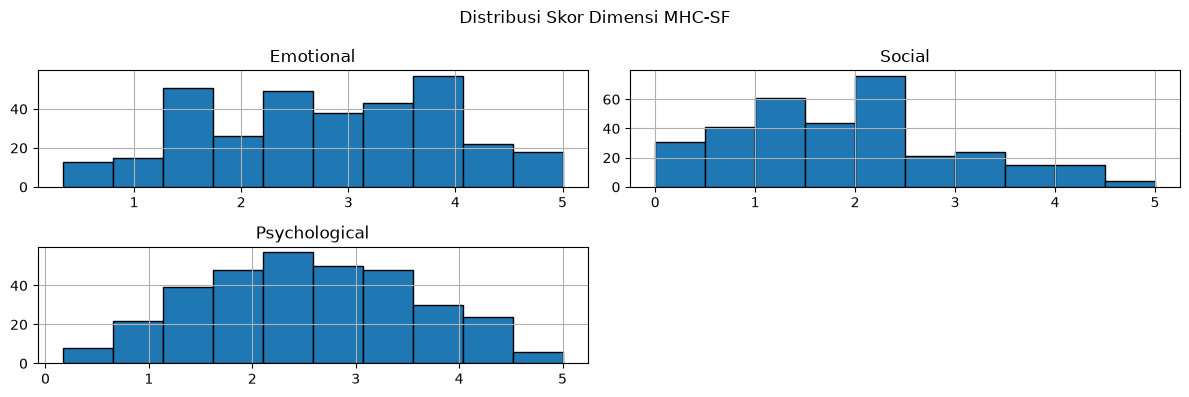

In [13]:
import matplotlib.pyplot as plt

features_3.hist(
    bins=10,
    figsize=(12, 4),
    edgecolor="black"
)

plt.suptitle("Distribusi Skor Dimensi MHC-SF")
plt.tight_layout()
plt.show()

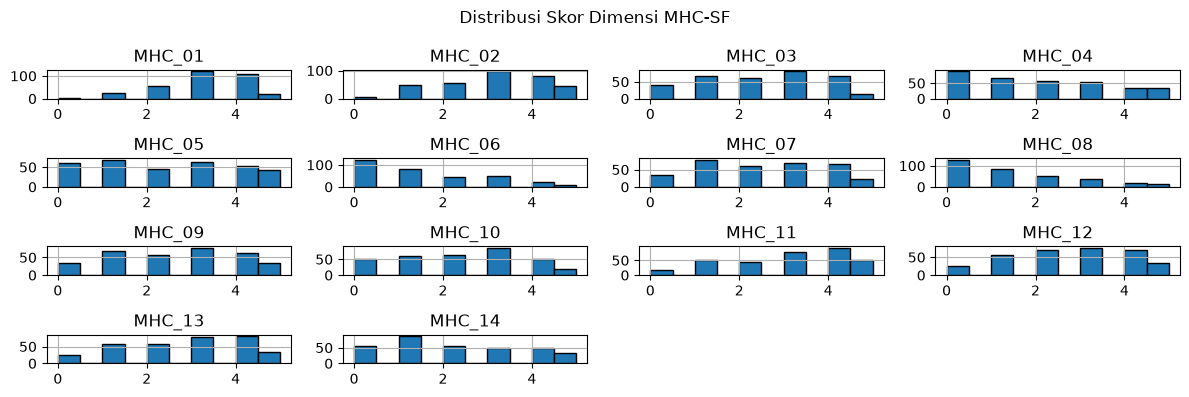

In [14]:
import matplotlib.pyplot as plt

features_14.hist(
    bins=10,
    figsize=(12, 4),
    edgecolor="black"
)

plt.suptitle("Distribusi Skor Dimensi MHC-SF")
plt.tight_layout()
plt.show()

In [15]:
# ==========================================
# 14. PEMERIKSAAN LIBRARY
# ==========================================
import os
os.environ["OMP_NUM_THREADS"] = "2"
import sklearn
import scipy
import importlib.util

print("PEMERIKSAAN LIBRARY ARUNA")
print("=" * 35)

print("Scikit-learn :", sklearn.__version__)
print("Scipy        :", scipy.__version__)

kmedoids_status = (
    importlib.util.find_spec("sklearn_extra") is not None
)


print("OMP_NUM_THREADS:", os.environ.get("OMP_NUM_THREADS"))
print(
    "K-Medoids    :",
    "Tersedia" if kmedoids_status else "Belum tersedia"
)

PEMERIKSAAN LIBRARY ARUNA
Scikit-learn : 1.9.0
Scipy        : 1.18.0
OMP_NUM_THREADS: 2
K-Medoids    : Belum tersedia


In [16]:
# ==========================================
# 15. PEMERIKSAAN KOMPATIBILITAS
# ==========================================

import sys
import numpy as np

print("INFORMASI LINGKUNGAN ARUNA")
print("=" * 40)

print("Python :", sys.version)
print("NumPy  :", np.__version__)
print("Scikit-learn :", sklearn.__version__)
print("SciPy  :", scipy.__version__)

INFORMASI LINGKUNGAN ARUNA
Python : 3.14.7 | packaged by Anaconda, Inc. | (main, Aug 14 2026, 10:12:46) [MSC v.1942 64 bit (AMD64)]
NumPy  : 2.5.1
Scikit-learn : 1.9.0
SciPy  : 1.18.0


In [17]:
# ==========================================
# 16. VALIDASI INSTALASI K-MEDOIDS
# ==========================================

import kmedoids
from importlib.metadata import version

print("K-Medoids berhasil diimpor!")
print("Versi:", version("kmedoids"))

K-Medoids berhasil diimpor!
Versi: 0.5.5


In [18]:
# ==========================================
# 17. KONFIGURASI EKSPERIMEN CLUSTERING
# ==========================================

# Konfigurasi eksperimen
RANDOM_STATE = 42
K_RANGE = range(2, 7)
DISTANCE_METRIC = "euclidean"

# Representasi fitur utama: 14 butir MHC-SF
X_14 = features_14.to_numpy(dtype=float)

# Representasi fitur pembanding: 3 dimensi MHC-SF
X_3 = features_3.to_numpy(dtype=float)

# Menampilkan konfigurasi
print("KONFIGURASI EKSPERIMEN ARUNA")
print("=" * 40)

print("Random state       :", RANDOM_STATE)
print("Rentang cluster    :", list(K_RANGE))
print("Metrik jarak       :", DISTANCE_METRIC)

print("\nREPRESENTASI A - 14 BUTIR MHC-SF")
print("Ukuran data        :", X_14.shape)
print("Nilai minimum      :", X_14.min())
print("Nilai maksimum     :", X_14.max())

print("\nREPRESENTASI B - 3 DIMENSI MHC-SF")
print("Ukuran data        :", X_3.shape)
print("Nilai minimum      :", X_3.min())
print("Nilai maksimum     :", X_3.max())

KONFIGURASI EKSPERIMEN ARUNA
Random state       : 42
Rentang cluster    : [2, 3, 4, 5, 6]
Metrik jarak       : euclidean

REPRESENTASI A - 14 BUTIR MHC-SF
Ukuran data        : (332, 14)
Nilai minimum      : 0.0
Nilai maksimum     : 5.0

REPRESENTASI B - 3 DIMENSI MHC-SF
Ukuran data        : (332, 3)
Nilai minimum      : 0.0
Nilai maksimum     : 5.0


In [19]:
# ==========================================
# 18. PEMBENTUKAN MATRIKS JARAK
# ==========================================

from sklearn.metrics.pairwise import euclidean_distances

# Matriks jarak untuk representasi 14 fitur
D_14 = euclidean_distances(X_14)

# Matriks jarak untuk representasi 3 dimensi
D_3 = euclidean_distances(X_3)

# Pemeriksaan matriks jarak
print("PEMERIKSAAN MATRIKS JARAK ARUNA")
print("=" * 40)

print("\nREPRESENTASI A - 14 BUTIR")
print("Ukuran matriks :", D_14.shape)
print("Nilai minimum  :", D_14.min())
print("Nilai maksimum :", D_14.max())
print("Simetris       :", np.allclose(D_14, D_14.T))
print("Diagonal nol   :", np.allclose(np.diag(D_14), 0))

print("\nREPRESENTASI B - 3 DIMENSI")
print("Ukuran matriks :", D_3.shape)
print("Nilai minimum  :", D_3.min())
print("Nilai maksimum :", D_3.max())
print("Simetris       :", np.allclose(D_3, D_3.T))
print("Diagonal nol   :", np.allclose(np.diag(D_3), 0))

PEMERIKSAAN MATRIKS JARAK ARUNA

REPRESENTASI A - 14 BUTIR
Ukuran matriks : (332, 332)
Nilai minimum  : 0.0
Nilai maksimum : 17.05872210923198
Simetris       : True
Diagonal nol   : True

REPRESENTASI B - 3 DIMENSI
Ukuran matriks : (332, 332)
Nilai minimum  : 0.0
Nilai maksimum : 7.885359147742663
Simetris       : True
Diagonal nol   : True


In [20]:
# ==========================================
# 19. - VALIDASI AKHIR DATA EKSPERIMEN
# ==========================================

print("VALIDASI AKHIR DATA ARUNA")
print("=" * 40)

# Validasi jumlah responden
print("Jumlah responden :", len(X_14))

# Validasi fitur
print("Jumlah fitur A   :", X_14.shape[1])
print("Jumlah fitur B   :", X_3.shape[1])

# Validasi missing value
print("Missing X_14     :", np.isnan(X_14).sum())
print("Missing X_3      :", np.isnan(X_3).sum())

# Validasi nilai tak hingga
print("Infinite X_14    :", np.isinf(X_14).sum())
print("Infinite X_3     :", np.isinf(X_3).sum())

# Validasi matriks jarak
print("Valid D_14       :", np.isfinite(D_14).all())
print("Valid D_3        :", np.isfinite(D_3).all())

print("\nVALIDASI SELESAI")

VALIDASI AKHIR DATA ARUNA
Jumlah responden : 332
Jumlah fitur A   : 14
Jumlah fitur B   : 3
Missing X_14     : 0
Missing X_3      : 0
Infinite X_14    : 0
Infinite X_3     : 0
Valid D_14       : True
Valid D_3        : True

VALIDASI SELESAI


In [23]:
# ==========================================
# 20. EKSPERIMEN K-MEANS
# ==========================================

from sklearn.cluster import KMeans

# Menyiapkan data hasil eksperimen
kmeans_results = {
    "A_14": {},
    "B_3": {}
}

# Menyiapkan data fitur
representations = {
    "A_14": X_14,
    "B_3": X_3
}

print("EKSPERIMEN K-MEANS ARUNA")
print("=" * 50)

# Eksperimen pada kedua representasi
for representation_name, X in representations.items():

    print(f"\nRepresentasi: {representation_name}")
    print("-" * 40)

    for k in K_RANGE:

        # Membuat model K-Means
        model = KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=20
        )

        # Melatih model
        labels = model.fit_predict(X)

        # Menyimpan model dan hasil clustering
        kmeans_results[representation_name][k] = {
            "model": model,
            "labels": labels,
            "inertia": model.inertia_
        }

        print(
            f"k = {k} | "
            f"Inertia = {model.inertia_:.4f}"
        )

print("\nSELURUH EKSPERIMEN K-MEANS SELESAI")

EKSPERIMEN K-MEANS ARUNA

Representasi: A_14
----------------------------------------
k = 2 | Inertia = 6701.0877
k = 3 | Inertia = 5846.7758
k = 4 | Inertia = 5493.0942
k = 5 | Inertia = 5211.4539
k = 6 | Inertia = 5034.2473

Representasi: B_3
----------------------------------------
k = 2 | Inertia = 554.6107
k = 3 | Inertia = 379.8958
k = 4 | Inertia = 321.3382
k = 5 | Inertia = 277.0725
k = 6 | Inertia = 243.2104

SELURUH EKSPERIMEN K-MEANS SELESAI


In [24]:
# ==========================================
# 21. PEMERIKSAAN DISTRIBUSI CLUSTER K-MEANS
# ==========================================

print("DISTRIBUSI CLUSTER K-MEANS ARUNA")
print("=" * 50)

for representation_name in kmeans_results:

    print(f"\nRepresentasi: {representation_name}")
    print("-" * 40)

    for k in K_RANGE:

        labels = kmeans_results[representation_name][k]["labels"]

        distribution = pd.Series(labels).value_counts().sort_index()

        print(f"\nk = {k}")

        for cluster, count in distribution.items():

            percentage = count / len(labels) * 100

            print(
                f"Cluster {cluster}: "
                f"{count} responden ({percentage:.2f}%)"
            )

DISTRIBUSI CLUSTER K-MEANS ARUNA

Representasi: A_14
----------------------------------------

k = 2
Cluster 0: 178 responden (53.61%)
Cluster 1: 154 responden (46.39%)

k = 3
Cluster 0: 76 responden (22.89%)
Cluster 1: 119 responden (35.84%)
Cluster 2: 137 responden (41.27%)

k = 4
Cluster 0: 99 responden (29.82%)
Cluster 1: 75 responden (22.59%)
Cluster 2: 105 responden (31.63%)
Cluster 3: 53 responden (15.96%)

k = 5
Cluster 0: 76 responden (22.89%)
Cluster 1: 53 responden (15.96%)
Cluster 2: 59 responden (17.77%)
Cluster 3: 73 responden (21.99%)
Cluster 4: 71 responden (21.39%)

k = 6
Cluster 0: 41 responden (12.35%)
Cluster 1: 64 responden (19.28%)
Cluster 2: 71 responden (21.39%)
Cluster 3: 48 responden (14.46%)
Cluster 4: 52 responden (15.66%)
Cluster 5: 56 responden (16.87%)

Representasi: B_3
----------------------------------------

k = 2
Cluster 0: 163 responden (49.10%)
Cluster 1: 169 responden (50.90%)

k = 3
Cluster 0: 137 responden (41.27%)
Cluster 1: 114 responden (34.3

In [25]:
# ==========================================
# 22 — EVALUASI METRIK KUALITAS CLUSTER K-MEANS
# ==========================================

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

kmeans_metrics = []

for representation_name, X in representations.items():

    for k in K_RANGE:

        labels = kmeans_results[representation_name][k]["labels"]

        silhouette = silhouette_score(X, labels, metric="euclidean")
        db_index = davies_bouldin_score(X, labels)
        ch_index = calinski_harabasz_score(X, labels)

        kmeans_metrics.append({
            "Representasi": representation_name,
            "Jumlah Cluster": k,
            "Silhouette Score": silhouette,
            "Davies-Bouldin Index": db_index,
            "Calinski-Harabasz Index": ch_index
        })

kmeans_metrics_df = pd.DataFrame(kmeans_metrics)

print("HASIL EVALUASI K-MEANS ARUNA")
print("=" * 90)

display(
    kmeans_metrics_df.round(4)
)

HASIL EVALUASI K-MEANS ARUNA


,Representasi,Jumlah Cluster,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,A_14,2,0.2634,1.3987,157.8932
1,A_14,3,0.1796,1.7741,114.2441
2,A_14,4,0.1420,2.0845,87.8598
3,A_14,5,0.1306,2.1745,73.6622
4,A_14,6,0.1148,2.3014,63.1126
5,B_3,2,0.4292,0.8497,391.7800
6,B_3,3,0.3616,0.9424,360.7675
7,B_3,4,0.2923,1.1068,303.3999
8,B_3,5,0.2988,1.1232,276.1597
9,B_3,6,0.2827,1.1136,259.9955


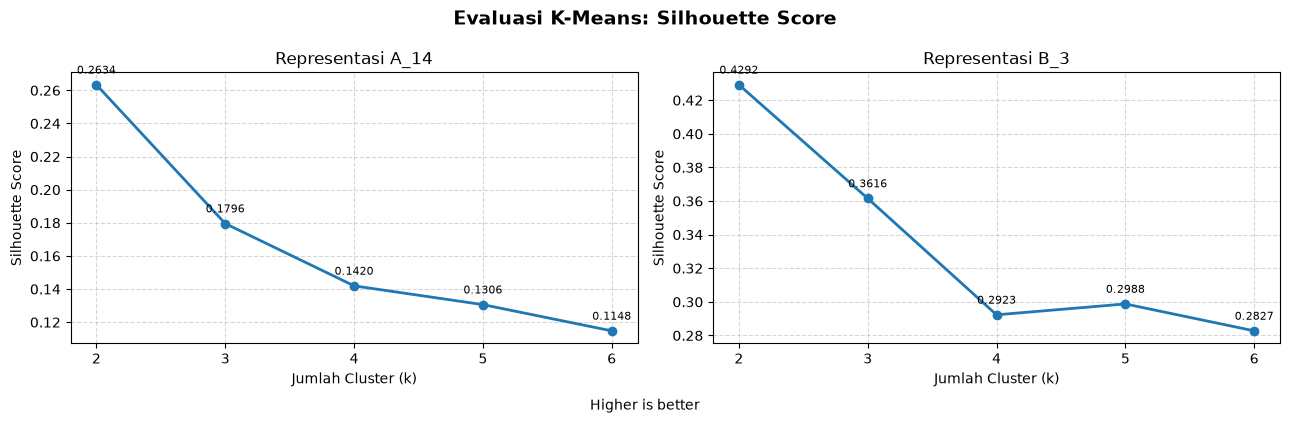

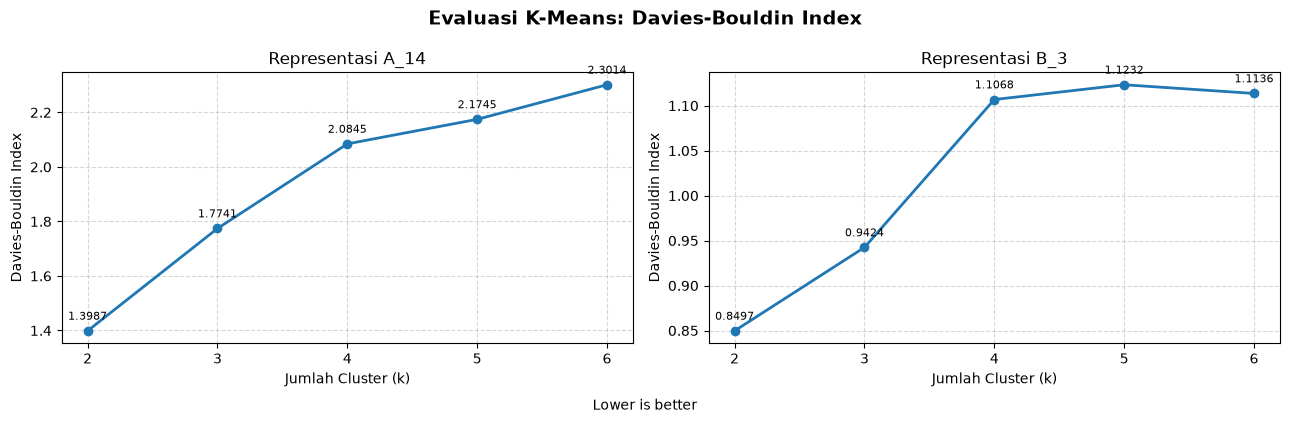

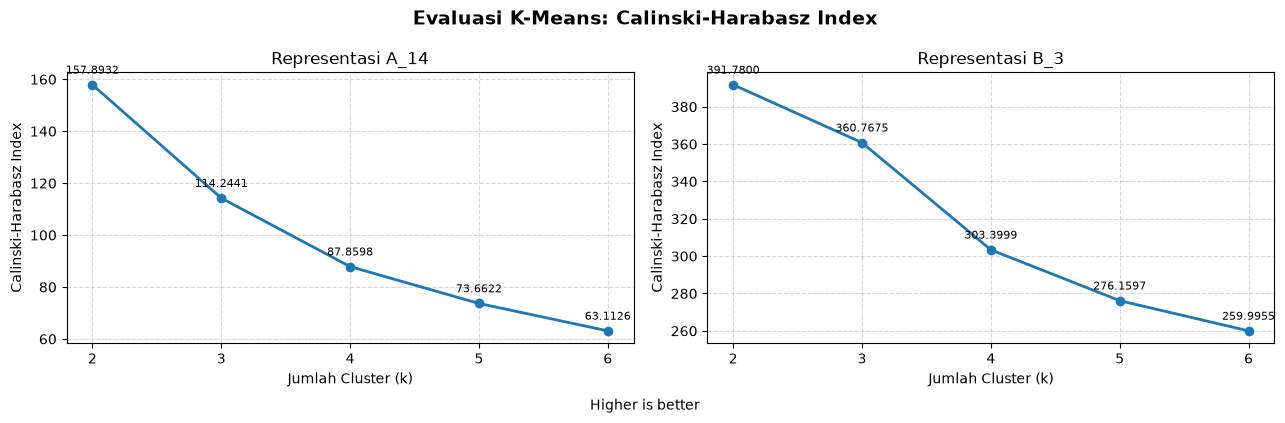

In [26]:
# ==========================================
# 23 — VISUALISASI EVALUASI K-MEANS
# ==========================================

# Menentukan metrik yang akan divisualisasikan
metrics_to_plot = [
    {
        "column": "Silhouette Score",
        "title": "Silhouette Score",
        "ylabel": "Silhouette Score",
        "better": "Higher is better"
    },
    {
        "column": "Davies-Bouldin Index",
        "title": "Davies-Bouldin Index",
        "ylabel": "Davies-Bouldin Index",
        "better": "Lower is better"
    },
    {
        "column": "Calinski-Harabasz Index",
        "title": "Calinski-Harabasz Index",
        "ylabel": "Calinski-Harabasz Index",
        "better": "Higher is better"
    }
]

representations_order = ["A_14", "B_3"]

# Membuat visualisasi untuk setiap metrik
for metric in metrics_to_plot:

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    fig.suptitle(
        f"Evaluasi K-Means: {metric['title']}",
        fontsize=14,
        fontweight="bold"
    )

    for ax, representation in zip(
        axes, representations_order
    ):

        subset = kmeans_metrics_df[
            kmeans_metrics_df["Representasi"] == representation
        ].sort_values("Jumlah Cluster")

        x = subset["Jumlah Cluster"]
        y = subset[metric["column"]]

        ax.plot(
            x,
            y,
            marker="o",
            linewidth=2
        )

        # Menampilkan nilai pada setiap titik
        for x_value, y_value in zip(x, y):

            ax.annotate(
                f"{y_value:.4f}",
                (x_value, y_value),
                textcoords="offset points",
                xytext=(0, 8),
                ha="center",
                fontsize=8
            )

        ax.set_title(f"Representasi {representation}")
        ax.set_xlabel("Jumlah Cluster (k)")
        ax.set_ylabel(metric["ylabel"])
        ax.set_xticks(list(K_RANGE))
        ax.grid(True, linestyle="--", alpha=0.5)

    fig.text(
        0.5,
        -0.02,
        metric["better"],
        ha="center",
        fontsize=10
    )

    plt.tight_layout()
    plt.show()


REPRESENTASI: A_14

Profil Cluster untuk k = 2


,Jumlah_Responden,Emotional,Social,Psychological
Cluster,,,,
0,178,2.056,1.144,1.772
1,154,3.677,2.7,3.444



Profil Cluster untuk k = 3


,Jumlah_Responden,Emotional,Social,Psychological
Cluster,,,,
0,76,4.083,3.321,3.912
1,119,1.756,0.882,1.471
2,137,3.015,1.912,2.725



REPRESENTASI: B_3

Profil Cluster untuk k = 2


,Jumlah_Responden,Emotional,Social,Psychological
Cluster,,,,
0,163,3.691,2.644,3.366
1,169,1.957,1.115,1.757



Profil Cluster untuk k = 3


,Jumlah_Responden,Emotional,Social,Psychological
Cluster,,,,
0,137,3.08,1.818,2.607
1,114,1.573,0.923,1.544
2,81,4.086,3.274,3.858


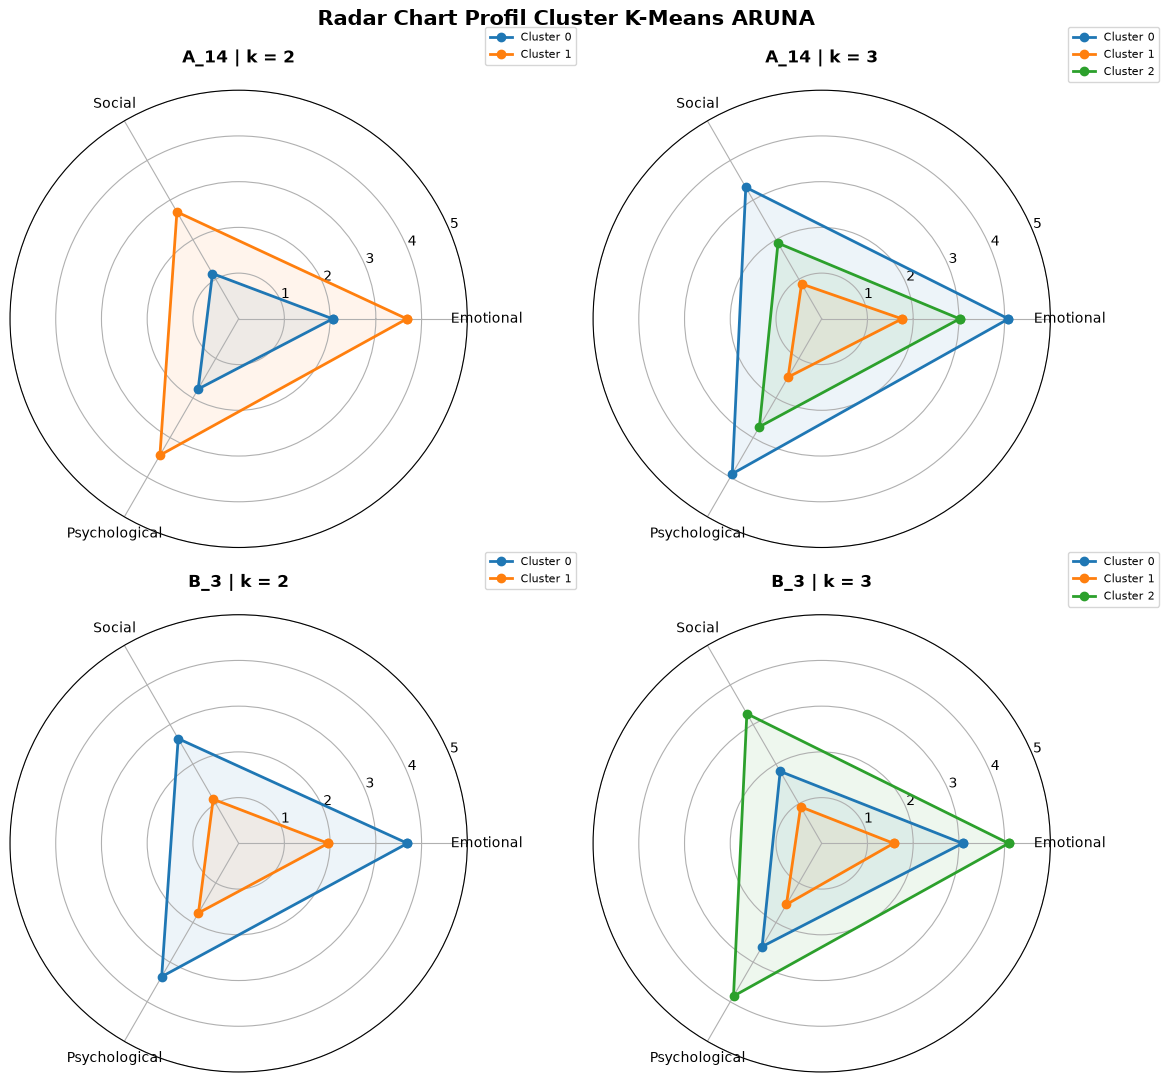

In [30]:
# ==========================================
# 24 — ANALISIS PROFIL DIMENSI CLUSTER K-MEANS
# ==========================================

dimension_names = [
    "Emotional",
    "Social",
    "Psychological"
]

for representation_name in ["A_14", "B_3"]:

    print(f"\nREPRESENTASI: {representation_name}")
    print("=" * 65)

    for k in [2, 3]:

        labels = kmeans_results[representation_name][k]["labels"]

        profile_df = features_3.copy()
        profile_df["Cluster"] = labels

        profile_summary = profile_df.groupby("Cluster").agg(
            Jumlah_Responden=("Cluster", "size"),
            Emotional=("Emotional", "mean"),
            Social=("Social", "mean"),
            Psychological=("Psychological", "mean")
        )

        print(f"\nProfil Cluster untuk k = {k}")
        display(profile_summary.round(3))

# ==========================================
# VISUALISASI RADAR CHART PROFIL K-MEANS
# ==========================================


dimensions = ["Emotional", "Social", "Psychological"]

# Data rata-rata tiga dimensi untuk setiap responden
profile_data = features_3[dimensions].copy()

representations_order = ["A_14", "B_3"]
k_values = [2, 3]

# Menentukan sudut setiap dimensi
angles = np.linspace(
    0,
    2 * np.pi,
    len(dimensions),
    endpoint=False
).tolist()

# Menutup bentuk radar
angles += angles[:1]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 11),
    subplot_kw={"polar": True}
)

for row, representation in enumerate(representations_order):

    for col, k in enumerate(k_values):

        ax = axes[row, col]

        # Mengambil label cluster
        labels = kmeans_results[representation][k]["labels"]

        # Menghitung rata-rata dimensi setiap cluster
        profile_df = profile_data.copy()
        profile_df["Cluster"] = labels

        cluster_profiles = (
            profile_df
            .groupby("Cluster")[dimensions]
            .mean()
        )

        # Menggambar profil masing-masing cluster
        for cluster, values in cluster_profiles.iterrows():

            values = values.tolist()
            values += values[:1]

            ax.plot(
                angles,
                values,
                linewidth=2,
                marker="o",
                label=f"Cluster {cluster}"
            )

            ax.fill(
                angles,
                values,
                alpha=0.08
            )

        ax.set_xticks(angles[:-1])
        ax.set_xticklabels(dimensions)

        ax.set_ylim(0, 5)
        ax.set_yticks([1, 2, 3, 4, 5])

        ax.set_title(
            f"{representation} | k = {k}",
            pad=20,
            fontsize=12,
            fontweight="bold"
        )

        ax.legend(
            loc="upper right",
            bbox_to_anchor=(1.25, 1.15),
            fontsize=8
        )

fig.suptitle(
    "Radar Chart Profil Cluster K-Means ARUNA",
    fontsize=15,
    fontweight="bold",
    y=0.98
)

plt.tight_layout()
plt.show()

In [31]:
# ==========================================
# 25 — Agglomerative Clustering
# ==========================================

from sklearn.cluster import AgglomerativeClustering

agglo_results = {
    "A_14": {},
    "B_3": {}
}

for representation_name, X in representations.items():
    for k in K_RANGE:
        model = AgglomerativeClustering(
            n_clusters=k,
            metric="euclidean",
            linkage="ward"
        )

        labels = model.fit_predict(X)

        agglo_results[representation_name][k] = {
            "model": model,
            "labels": labels
        }

print("Eksperimen Agglomerative Clustering selesai.")

for representation_name in agglo_results:
    print(f"\nRepresentasi {representation_name}")

    for k, result in agglo_results[representation_name].items():
        labels = result["labels"]
        unique, counts = np.unique(labels, return_counts=True)

        print(f"\nk={k}")
        for cluster, count in zip(unique, counts):
            print(
                f"Cluster {cluster}: {count} responden "
                f"({count / len(labels) * 100:.2f}%)"
            )


Eksperimen Agglomerative Clustering selesai.

Representasi A_14

k=2
Cluster 0: 209 responden (62.95%)
Cluster 1: 123 responden (37.05%)

k=3
Cluster 0: 141 responden (42.47%)
Cluster 1: 123 responden (37.05%)
Cluster 2: 68 responden (20.48%)

k=4
Cluster 0: 123 responden (37.05%)
Cluster 1: 98 responden (29.52%)
Cluster 2: 68 responden (20.48%)
Cluster 3: 43 responden (12.95%)

k=5
Cluster 0: 98 responden (29.52%)
Cluster 1: 69 responden (20.78%)
Cluster 2: 68 responden (20.48%)
Cluster 3: 43 responden (12.95%)
Cluster 4: 54 responden (16.27%)

k=6
Cluster 0: 69 responden (20.78%)
Cluster 1: 72 responden (21.69%)
Cluster 2: 68 responden (20.48%)
Cluster 3: 43 responden (12.95%)
Cluster 4: 54 responden (16.27%)
Cluster 5: 26 responden (7.83%)

Representasi B_3

k=2
Cluster 0: 216 responden (65.06%)
Cluster 1: 116 responden (34.94%)

k=3
Cluster 0: 129 responden (38.86%)
Cluster 1: 116 responden (34.94%)
Cluster 2: 87 responden (26.20%)

k=4
Cluster 0: 116 responden (34.94%)
Cluster 1: 

In [32]:
# ==========================================
# 26 — Evaluasi Metrik Agglomerative Clustering
# ==========================================

agglo_metrics = []

for representation_name, X in representations.items():
    for k, result in agglo_results[representation_name].items():
        labels = result["labels"]

        agglo_metrics.append({
            "Representation": representation_name,
            "K": k,
            "Silhouette Score": silhouette_score(
                X, labels, metric="euclidean"
            ),
            "Davies-Bouldin Index": davies_bouldin_score(
                X, labels
            ),
            "Calinski-Harabasz Index": calinski_harabasz_score(
                X, labels
            )
        })

agglo_metrics_df = pd.DataFrame(agglo_metrics)

display(
    agglo_metrics_df.round(4)
)


,Representation,K,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,A_14,2,0.2382,1.4411,133.8483
1,A_14,3,0.1643,1.7872,105.0308
2,A_14,4,0.1135,2.2737,79.1605
3,A_14,5,0.0809,2.4067,66.0263
4,A_14,6,0.0908,2.4059,57.2821
5,B_3,2,0.3942,0.8532,305.8725
6,B_3,3,0.3354,1.0195,329.4470
7,B_3,4,0.3219,1.1030,271.2884
8,B_3,5,0.2866,1.1541,244.0759
9,B_3,6,0.2513,1.1684,228.6403


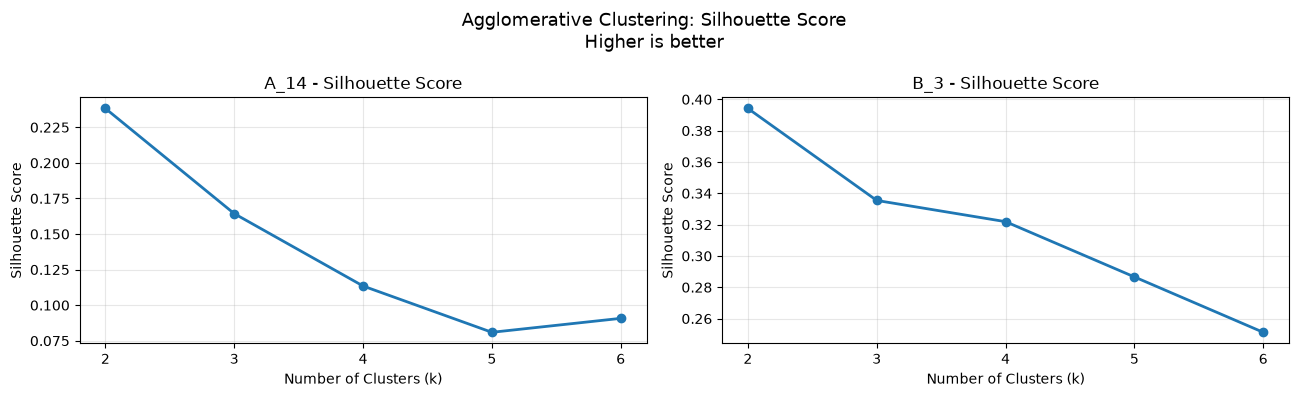

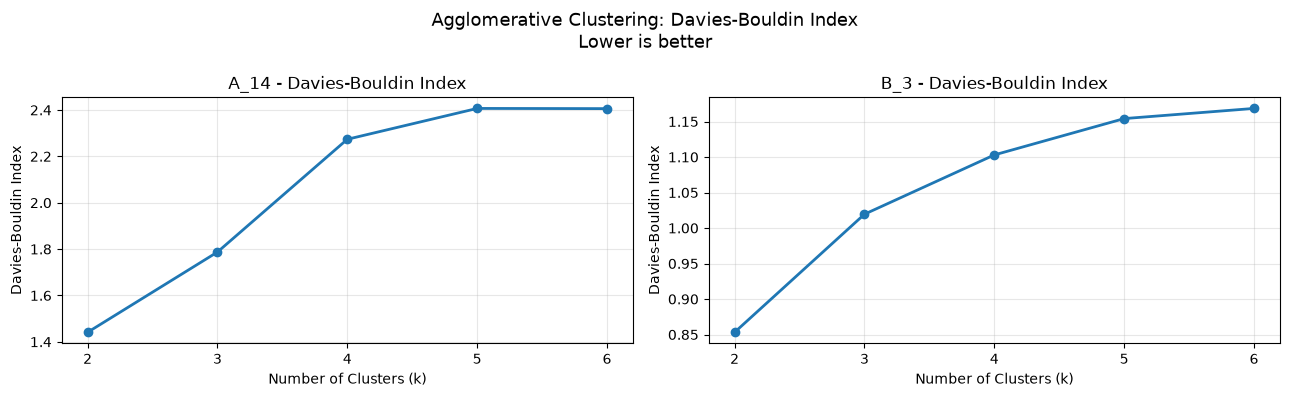

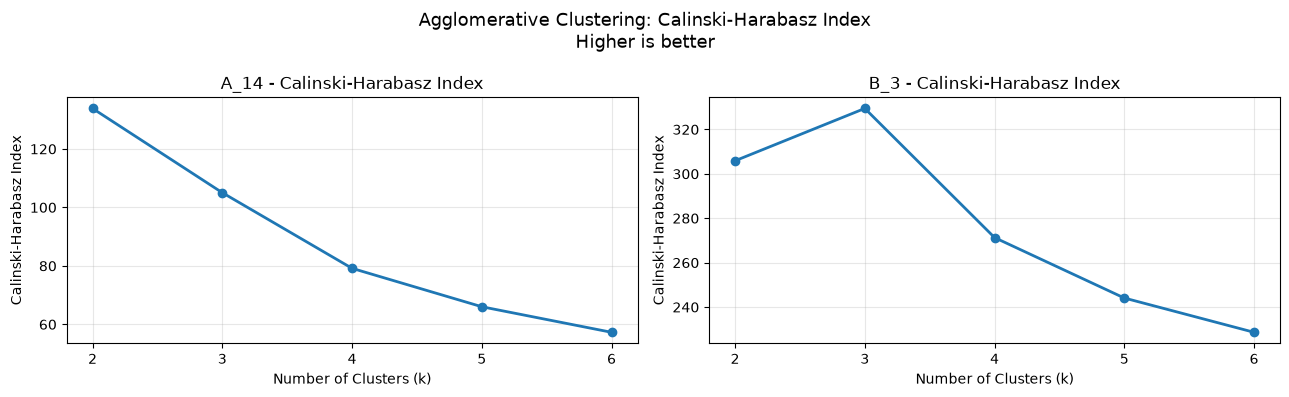

In [33]:

metrics_to_plot = [
    {
        "column": "Silhouette Score",
        "title": "Silhouette Score",
        "ylabel": "Silhouette Score",
        "better": "Higher is better"
    },
    {
        "column": "Davies-Bouldin Index",
        "title": "Davies-Bouldin Index",
        "ylabel": "Davies-Bouldin Index",
        "better": "Lower is better"
    },
    {
        "column": "Calinski-Harabasz Index",
        "title": "Calinski-Harabasz Index",
        "ylabel": "Calinski-Harabasz Index",
        "better": "Higher is better"
    }
]

representations_order = ["A_14", "B_3"]

for metric in metrics_to_plot:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    for ax, representation in zip(axes, representations_order):
        subset = agglo_metrics_df[
            agglo_metrics_df["Representation"] == representation
        ]

        ax.plot(
            subset["K"],
            subset[metric["column"]],
            marker="o",
            linewidth=2
        )

        ax.set_title(
            f'{representation} - {metric["title"]}'
        )
        ax.set_xlabel("Number of Clusters (k)")
        ax.set_ylabel(metric["ylabel"])
        ax.set_xticks(list(K_RANGE))
        ax.grid(True, alpha=0.3)

    fig.suptitle(
        f'Agglomerative Clustering: {metric["title"]}\n'
        f'{metric["better"]}',
        fontsize=13
    )

    plt.tight_layout()
    plt.show()


In [34]:
# ==========================================
# 27 — Profil Cluster Agglomerative Clustering
# ==========================================

agglo_profiles = []

for representation_name in representations:
    for k in [2, 3]:
        labels = agglo_results[representation_name][k]["labels"]

        temp_df = features_3.reset_index(drop=True).copy()
        temp_df["Cluster"] = labels

        profile = temp_df.groupby("Cluster").agg(
            Jumlah_Responden=("Cluster", "size"),
            Emotional=("Emotional", "mean"),
            Social=("Social", "mean"),
            Psychological=("Psychological", "mean")
        ).reset_index()

        profile.insert(0, "Representation", representation_name)
        profile.insert(1, "K", k)

        agglo_profiles.append(profile)

agglo_profiles_df = pd.concat(
    agglo_profiles,
    ignore_index=True
)

display(agglo_profiles_df.round(3))


,Representation,K,Cluster,Jumlah_Responden,Emotional,Social,Psychological
0,A_14,2,0,209,3.388,2.422,3.159
1,A_14,2,1,123,1.824,0.92,1.507
2,A_14,3,0,141,3.083,1.925,2.811
3,A_14,3,1,123,1.824,0.92,1.507
4,A_14,3,2,68,4.02,3.453,3.882
5,B_3,2,0,216,3.366,2.436,3.102
6,B_3,2,1,116,1.77,0.803,1.514
7,B_3,3,0,129,2.925,1.921,2.607
8,B_3,3,1,116,1.77,0.803,1.514
9,B_3,3,2,87,4.019,3.2,3.835


In [36]:
# ==========================================
# 28 — K Medoids
# ==========================================

# Matriks jarak yang sudah dihitung sebelumnya
distance_matrices = {
    "A_14": D_14,
    "B_3": D_3
}

kmedoids_results = {
    "A_14": {},
    "B_3": {}
}

for representation_name, D in distance_matrices.items():
    for k in K_RANGE:

        model = kmedoids.KMedoids(
            n_clusters=k,
            metric="precomputed",
            method="fasterpam",
            init="build",
            max_iter=300,
            random_state=RANDOM_STATE
        )

        labels = model.fit_predict(D)

        kmedoids_results[representation_name][k] = {
            "model": model,
            "labels": labels,
            "inertia": model.inertia_
        }

print("Eksperimen K-Medoids selesai.")

for representation_name in kmedoids_results:
    print(f"\nRepresentasi {representation_name}")

    for k, result in kmedoids_results[representation_name].items():
        labels = result["labels"]
        unique, counts = np.unique(labels, return_counts=True)

        print(f"\nk={k}")
        print(f"Objective value: {result['inertia']:.4f}")

        for cluster, count in zip(unique, counts):
            print(
                f"Cluster {cluster}: {count} responden "
                f"({count / len(labels) * 100:.2f}%)"
            )


Eksperimen K-Medoids selesai.

Representasi A_14

k=2
Objective value: 1548.6903
Cluster 0: 158 responden (47.59%)
Cluster 1: 174 responden (52.41%)

k=3
Objective value: 1470.0805
Cluster 0: 124 responden (37.35%)
Cluster 1: 153 responden (46.08%)
Cluster 2: 55 responden (16.57%)

k=4
Objective value: 1419.4280
Cluster 0: 124 responden (37.35%)
Cluster 1: 109 responden (32.83%)
Cluster 2: 55 responden (16.57%)
Cluster 3: 44 responden (13.25%)

k=5
Objective value: 1373.6360
Cluster 0: 78 responden (23.49%)
Cluster 1: 106 responden (31.93%)
Cluster 2: 45 responden (13.55%)
Cluster 3: 44 responden (13.25%)
Cluster 4: 59 responden (17.77%)

k=6
Objective value: 1343.1828
Cluster 0: 67 responden (20.18%)
Cluster 1: 82 responden (24.70%)
Cluster 2: 45 responden (13.55%)
Cluster 3: 39 responden (11.75%)
Cluster 4: 43 responden (12.95%)
Cluster 5: 56 responden (16.87%)

Representasi B_3

k=2
Objective value: 397.0448
Cluster 0: 161 responden (48.49%)
Cluster 1: 171 responden (51.51%)

k=3
Ob

In [37]:
# ==========================================
# 29 — Evaluasi Metrik K Medoids
# ==========================================
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

kmedoids_metrics = []

for representation_name, X in representations.items():
    for k, result in kmedoids_results[representation_name].items():
        labels = result["labels"]

        kmedoids_metrics.append({
            "Representation": representation_name,
            "K": k,
            "Silhouette Score": silhouette_score(
                X, labels, metric="euclidean"
            ),
            "Davies-Bouldin Index": davies_bouldin_score(
                X, labels
            ),
            "Calinski-Harabasz Index": calinski_harabasz_score(
                X, labels
            )
        })

kmedoids_metrics_df = pd.DataFrame(kmedoids_metrics)

display(kmedoids_metrics_df.round(4))


,Representation,K,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,A_14,2,0.2606,1.4113,155.5457
1,A_14,3,0.1751,1.7093,106.2776
2,A_14,4,0.1075,2.1505,80.1905
3,A_14,5,0.0826,2.5587,65.1805
4,A_14,6,0.0877,2.5361,57.4671
5,B_3,2,0.4290,0.8501,391.6915
6,B_3,3,0.3549,0.9636,357.9234
7,B_3,4,0.2891,1.1741,295.4214
8,B_3,5,0.2732,1.2018,269.6667
9,B_3,6,0.2680,1.1882,245.6541


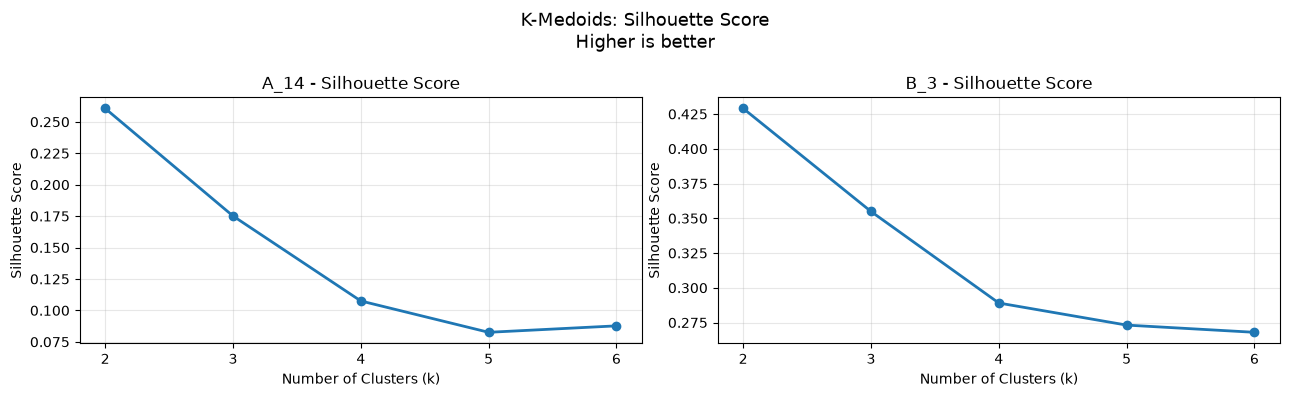

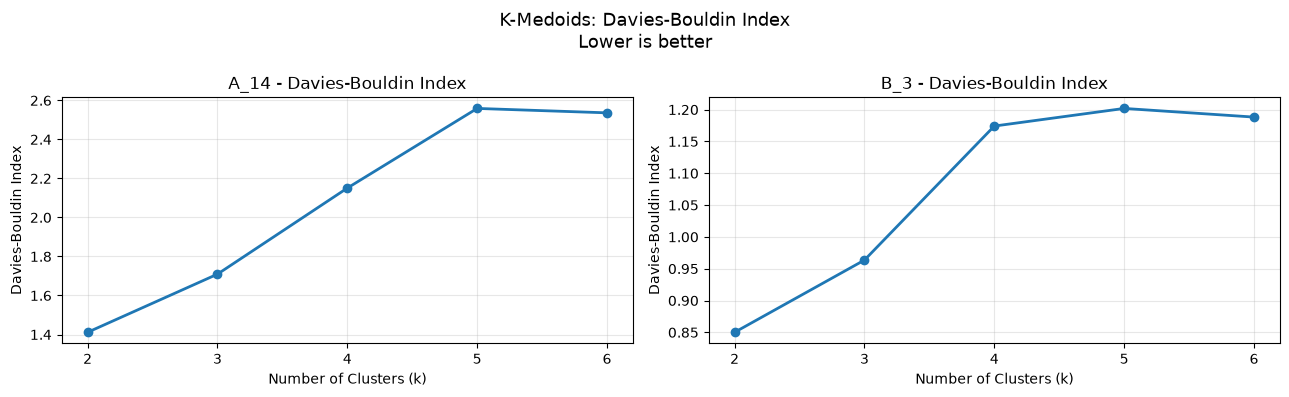

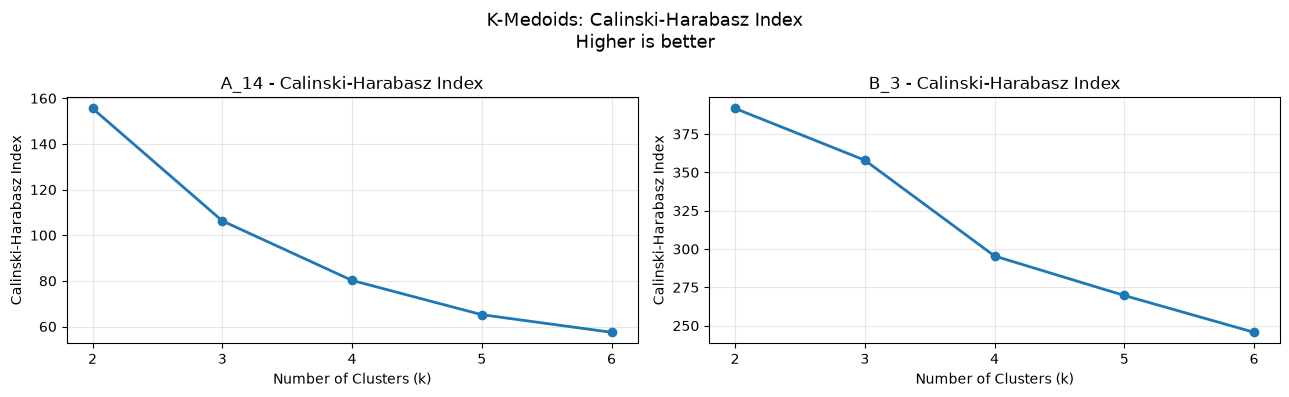

In [38]:

import matplotlib.pyplot as plt

metrics_to_plot = [
    {
        "column": "Silhouette Score",
        "title": "Silhouette Score",
        "ylabel": "Silhouette Score",
        "better": "Higher is better"
    },
    {
        "column": "Davies-Bouldin Index",
        "title": "Davies-Bouldin Index",
        "ylabel": "Davies-Bouldin Index",
        "better": "Lower is better"
    },
    {
        "column": "Calinski-Harabasz Index",
        "title": "Calinski-Harabasz Index",
        "ylabel": "Calinski-Harabasz Index",
        "better": "Higher is better"
    }
]

representations_order = ["A_14", "B_3"]

for metric in metrics_to_plot:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    for ax, representation in zip(
        axes, representations_order
    ):
        subset = kmedoids_metrics_df[
            kmedoids_metrics_df["Representation"] == representation
        ]

        ax.plot(
            subset["K"],
            subset[metric["column"]],
            marker="o",
            linewidth=2
        )

        ax.set_title(
            f'{representation} - {metric["title"]}'
        )
        ax.set_xlabel("Number of Clusters (k)")
        ax.set_ylabel(metric["ylabel"])
        ax.set_xticks(list(K_RANGE))
        ax.grid(True, alpha=0.3)

    fig.suptitle(
        f'K-Medoids: {metric["title"]}\n{metric["better"]}',
        fontsize=13
    )

    plt.tight_layout()
    plt.show()


In [39]:
# ==========================================
# 30 — Profil Kluster K Medoids
# ==========================================
kmedoids_profiles = []

for representation_name in representations:
    for k in [2, 3]:
        labels = kmedoids_results[representation_name][k]["labels"]

        temp_df = features_3.reset_index(drop=True).copy()
        temp_df["Cluster"] = labels

        profile = temp_df.groupby("Cluster").agg(
            Jumlah_Responden=("Cluster", "size"),
            Emotional=("Emotional", "mean"),
            Social=("Social", "mean"),
            Psychological=("Psychological", "mean")
        ).reset_index()

        profile.insert(0, "Representation", representation_name)
        profile.insert(1, "K", k)

        kmedoids_profiles.append(profile)

kmedoids_profiles_df = pd.concat(
    kmedoids_profiles,
    ignore_index=True
)

display(kmedoids_profiles_df.round(3))


,Representation,K,Cluster,Jumlah_Responden,Emotional,Social,Psychological
0,A_14,2,0,158,3.673,2.665,3.412
1,A_14,2,1,174,2.023,1.14,1.761
2,A_14,3,0,124,3.301,2.045,3.043
3,A_14,3,1,153,1.935,1.078,1.644
4,A_14,3,2,55,4.127,3.651,3.942
5,B_3,2,0,161,3.708,2.66,3.363
6,B_3,2,1,171,1.961,1.118,1.779
7,B_3,3,0,132,3.008,1.761,2.566
8,B_3,3,1,110,1.567,0.915,1.495
9,B_3,3,2,90,4.033,3.182,3.806


In [40]:
from itertools import combinations
from sklearn.metrics import adjusted_rand_score

N_RUNS = 30
SAMPLE_SIZE = int(0.8 * len(X_3))
RANDOM_STATE_STABILITY = 42

rng = np.random.default_rng(RANDOM_STATE_STABILITY)

algorithms = ["K-Means", "K-Medoids", "Agglomerative"]
stability_labels = {name: [] for name in algorithms}

for run in range(N_RUNS):

    indices = np.sort(
        rng.choice(len(X_3), size=SAMPLE_SIZE, replace=False)
    )

    X_sample = X_3[indices]

    # K-Means
    km = KMeans(
        n_clusters=2,
        random_state=RANDOM_STATE + run,
        n_init=20
    )
    labels_km = km.fit_predict(X_sample)

    # K-Medoids
    D_sample = D_3[np.ix_(indices, indices)]

    kmed = kmedoids.KMedoids(
        n_clusters=2,
        metric="precomputed",
        method="fasterpam",
        init="build",
        max_iter=300,
        random_state=RANDOM_STATE + run
    )
    labels_kmed = kmed.fit_predict(D_sample)

    # Agglomerative
    agg = AgglomerativeClustering(
        n_clusters=2,
        metric="euclidean",
        linkage="ward"
    )
    labels_agg = agg.fit_predict(X_sample)

    for name, labels in zip(
        algorithms,
        [labels_km, labels_kmed, labels_agg]
    ):
        stability_labels[name].append({
            "indices": indices.copy(),
            "labels": labels.copy()
        })

# Membandingkan hasil antarpercobaan
stability_results = []

for name in algorithms:
    ari_scores = []

    for run_a, run_b in combinations(
        stability_labels[name], 2
    ):
        common, pos_a, pos_b = np.intersect1d(
            run_a["indices"],
            run_b["indices"],
            return_indices=True
        )

        ari = adjusted_rand_score(
            run_a["labels"][pos_a],
            run_b["labels"][pos_b]
        )

        ari_scores.append(ari)

    stability_results.append({
        "Algorithm": name,
        "Mean ARI": np.mean(ari_scores),
        "Std ARI": np.std(ari_scores),
        "Min ARI": np.min(ari_scores),
        "Max ARI": np.max(ari_scores)
    })

stability_df = pd.DataFrame(stability_results)

display(stability_df.round(4))


,Algorithm,Mean ARI,Std ARI,Min ARI,Max ARI
0,K-Means,0.9088,0.0875,0.5298,1.0
1,K-Medoids,0.9008,0.0856,0.6851,1.0
2,Agglomerative,0.4800,0.3489,-0.0341,1.0


In [42]:


N_RUNS = 30
SAMPLE_SIZE = int(0.8 * len(X_3))
RANDOM_STATE_STABILITY = 42

rng = np.random.default_rng(RANDOM_STATE_STABILITY)

stability_labels_k3 = []

for run in range(N_RUNS):

    indices = np.sort(
        rng.choice(
            len(X_3),
            size=SAMPLE_SIZE,
            replace=False
        )
    )

    X_sample = X_3[indices]

    model = KMeans(
        n_clusters=3,
        random_state=RANDOM_STATE + run,
        n_init=20
    )

    labels = model.fit_predict(X_sample)

    stability_labels_k3.append({
        "indices": indices.copy(),
        "labels": labels.copy()
    })

# Membandingkan hasil antarpercobaan
ari_scores_k3 = []

for run_a, run_b in combinations(stability_labels_k3, 2):

    common, pos_a, pos_b = np.intersect1d(
        run_a["indices"],
        run_b["indices"],
        return_indices=True
    )

    ari = adjusted_rand_score(
        run_a["labels"][pos_a],
        run_b["labels"][pos_b]
    )

    ari_scores_k3.append(ari)

# Ringkasan stabilitas
stability_k3_df = pd.DataFrame([{
    "Algorithm": "K-Means",
    "Representation": "B_3",
    "K": 3,
    "Mean ARI": np.mean(ari_scores_k3),
    "Std ARI": np.std(ari_scores_k3),
    "Min ARI": np.min(ari_scores_k3),
    "Max ARI": np.max(ari_scores_k3)
}])

display(stability_k3_df.round(4))


,Algorithm,Representation,K,Mean ARI,Std ARI,Min ARI,Max ARI
0,K-Means,B_3,3,0.8955,0.0844,0.5931,1.0


In [43]:

import numpy as np
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Melatih ulang kandidat model K-Means
final_candidate = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

candidate_labels = final_candidate.fit_predict(X_3)

# Menghitung metrik evaluasi
candidate_metrics = {
    "Silhouette Score": silhouette_score(X_3, candidate_labels),
    "Davies-Bouldin Index": davies_bouldin_score(X_3, candidate_labels),
    "Calinski-Harabasz Index": calinski_harabasz_score(
        X_3, candidate_labels
    )
}

print("HASIL EVALUASI KANDIDAT K-MEANS")
for metric, value in candidate_metrics.items():
    print(f"{metric}: {value:.4f}")

# Membentuk tabel profil cluster
profile_data = pd.DataFrame(
    X_3,
    columns=["Emotional", "Social", "Psychological"]
)

profile_data["Cluster"] = candidate_labels

print("\nJUMLAH ANGGOTA SETIAP CLUSTER")
print(profile_data["Cluster"].value_counts().sort_index())

print("\nRATA-RATA DIMENSI SETIAP CLUSTER")
display(
    profile_data.groupby("Cluster")[
        ["Emotional", "Social", "Psychological"]
    ].mean().round(3)
)


HASIL EVALUASI KANDIDAT K-MEANS
Silhouette Score: 0.4292
Davies-Bouldin Index: 0.8497
Calinski-Harabasz Index: 391.7800

JUMLAH ANGGOTA SETIAP CLUSTER
Cluster
0    163
1    169
Name: count, dtype: int64

RATA-RATA DIMENSI SETIAP CLUSTER


,Emotional,Social,Psychological
Cluster,,,
0,3.691,2.644,3.366
1,1.957,1.115,1.757


In [45]:

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import pandas as pd

# Menghitung skor kesejahteraan keseluruhan
overall_score = X_3.mean(axis=1).reshape(-1, 1)

# Clustering berdasarkan satu skor keseluruhan
overall_model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

overall_labels = overall_model.fit_predict(overall_score)

# Membandingkan hasil kedua pendekatan
ari_comparison = adjusted_rand_score(
    candidate_labels,
    overall_labels
)

print(f"ARI antara clustering 3 dimensi dan 1 skor: {ari_comparison:.4f}")

# Melihat kesesuaian keanggotaan cluster
comparison_table = pd.crosstab(
    pd.Series(candidate_labels, name="Cluster 3 Dimensi"),
    pd.Series(overall_labels, name="Cluster 1 Skor")
)

print("\nPERBANDINGAN KEANGGOTAAN CLUSTER")
display(comparison_table)

# Profil cluster berdasarkan satu skor
comparison_df = pd.DataFrame({
    "Overall Score": overall_score.flatten(),
    "Cluster 1 Skor": overall_labels
})

print("\nRATA-RATA SKOR KESELURUHAN")
display(
    comparison_df.groupby("Cluster 1 Skor")[
        ["Overall Score"]
    ].mean().round(3)
)


ARI antara clustering 3 dimensi dan 1 skor: 0.9405

PERBANDINGAN KEANGGOTAAN CLUSTER


Cluster 1 Skor,0,1
Cluster 3 Dimensi,,
0,5,158
1,169,0



RATA-RATA SKOR KESELURUHAN


,Overall Score
Cluster 1 Skor,
0,1.633
1,3.259


In [46]:
#Analisis Tambahan

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import pandas as pd

# Menghitung rata-rata tiga dimensi setiap responden
personal_mean = X_3.mean(axis=1, keepdims=True)

# Menghitung penyimpangan relatif setiap dimensi
X_relative = X_3 - personal_mean

# Menguji beberapa jumlah cluster
relative_results = []
relative_models = {}

for k in range(2, 6):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_relative)
    relative_models[k] = (model, labels)

    relative_results.append({
        "K": k,
        "Silhouette": silhouette_score(X_relative, labels),
        "Davies-Bouldin": davies_bouldin_score(X_relative, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_relative, labels)
    })

relative_metrics = pd.DataFrame(relative_results).round(4)

print("EVALUASI CLUSTERING POLA RELATIF")
display(relative_metrics)


EVALUASI CLUSTERING POLA RELATIF


,K,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2,0.3576,1.0742,211.4672
1,3,0.3411,0.9594,202.7470
2,4,0.3363,0.9469,201.1128
3,5,0.3264,0.9257,195.3385


In [47]:

dimensions = ["Emotional", "Social", "Psychological"]

for k in [2, 3]:
    model, labels = relative_models[k]

    result = pd.DataFrame(X_3, columns=dimensions)
    result["Cluster"] = labels

    relative_profile = pd.DataFrame(
        X_relative,
        columns=dimensions
    )
    relative_profile["Cluster"] = labels

    print(f"\n{'='*15} K = {k} {'='*15}")

    print("\nJUMLAH ANGGOTA CLUSTER")
    print(result["Cluster"].value_counts().sort_index())

    print("\nRATA-RATA SKOR ASLI")
    display(
        result.groupby("Cluster")[dimensions]
        .mean()
        .round(3)
    )

    print("\nRATA-RATA POLA RELATIF")
    display(
        relative_profile.groupby("Cluster")[dimensions]
        .mean()
        .round(3)
    )



=============== K = 2 ===============

JUMLAH ANGGOTA CLUSTER
Cluster
0    158
1    174
Name: count, dtype: int64

RATA-RATA SKOR ASLI


,Emotional,Social,Psychological
Cluster,,,
0,2.352,2.208,2.502
1,3.222,1.555,2.588



RATA-RATA POLA RELATIF


,Emotional,Social,Psychological
Cluster,,,
0,-0.002,-0.146,0.148
1,0.767,-0.900,0.133



=============== K = 3 ===============

JUMLAH ANGGOTA CLUSTER
Cluster
0    100
1    121
2    111
Name: count, dtype: int64

RATA-RATA SKOR ASLI


,Emotional,Social,Psychological
Cluster,,,
0,2.970,1.472,3.068
1,2.361,2.388,2.519
2,3.150,1.650,2.108



RATA-RATA POLA RELATIF


,Emotional,Social,Psychological
Cluster,,,
0,0.467,-1.031,0.565
1,-0.062,-0.034,0.096
2,0.847,-0.652,-0.195


In [48]:

import numpy as np
from itertools import combinations
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

rng = np.random.default_rng(42)
stability_results = []

for k in [2, 3]:
    runs = []

    for run in range(30):
        indices = rng.choice(
            len(X_relative),
            size=int(0.8 * len(X_relative)),
            replace=False
        )

        model = KMeans(
            n_clusters=k,
            random_state=42 + run,
            n_init=20
        )

        labels = model.fit_predict(X_relative[indices])
        runs.append((indices, labels))

    ari_scores = []

    for (idx_a, labels_a), (idx_b, labels_b) in combinations(runs, 2):
        common, pos_a, pos_b = np.intersect1d(
            idx_a,
            idx_b,
            return_indices=True
        )

        ari = adjusted_rand_score(
            labels_a[pos_a],
            labels_b[pos_b]
        )
        ari_scores.append(ari)

    stability_results.append({
        "K": k,
        "Mean ARI": np.mean(ari_scores),
        "Std ARI": np.std(ari_scores),
        "Min ARI": np.min(ari_scores),
        "Max ARI": np.max(ari_scores)
    })

print("STABILITAS CLUSTERING POLA RELATIF")
display(pd.DataFrame(stability_results).round(4))


STABILITAS CLUSTERING POLA RELATIF


,K,Mean ARI,Std ARI,Min ARI,Max ARI
0,2,0.8778,0.0890,0.5802,1.0
1,3,0.7836,0.2426,0.2539,1.0


In [49]:

# Mengambil label dari kedua model
relative_labels = relative_models[2][1]

# Membuat tabel gabungan
combined_df = pd.DataFrame({
    "Overall Cluster": candidate_labels,
    "Pattern Cluster": relative_labels,
    "Overall Score": X_3.mean(axis=1)
})

print("PERBANDINGAN TINGKAT DAN POLA KESEJAHTERAAN")
display(
    pd.crosstab(
        combined_df["Overall Cluster"],
        combined_df["Pattern Cluster"]
    )
)

print("\nRATA-RATA SKOR KESELURUHAN BERDASARKAN POLA")
display(
    combined_df.groupby("Pattern Cluster")[
        ["Overall Score"]
    ].agg(["mean", "std", "min", "max"]).round(3)
)

print("\nDISTRIBUSI POLA DALAM SETIAP TINGKAT KESEJAHTERAAN (%)")
display(
    pd.crosstab(
        combined_df["Overall Cluster"],
        combined_df["Pattern Cluster"],
        normalize="index"
    ).mul(100).round(2)
)


PERBANDINGAN TINGKAT DAN POLA KESEJAHTERAAN


Pattern Cluster,0,1
Overall Cluster,,
0,66,97
1,92,77



RATA-RATA SKOR KESELURUHAN BERDASARKAN POLA


Overall Score                     
                         mean    std    min    max
Pattern Cluster                                   
0                       2.354  1.115  0.456  5.000
1                       2.455  0.855  0.678  4.667


DISTRIBUSI POLA DALAM SETIAP TINGKAT KESEJAHTERAAN (%)


Pattern Cluster,0,1
Overall Cluster,,
0,40.49,59.51
1,54.44,45.56


In [50]:

# Membentuk tabel profil pola relatif K=2
pattern_labels = relative_models[2][1]

pattern_df = pd.DataFrame(
    X_relative,
    columns=["Emotional", "Social", "Psychological"]
)

pattern_df["Pattern Cluster"] = pattern_labels

# Rata-rata pola relatif
pattern_profile = pattern_df.groupby(
    "Pattern Cluster"
)[["Emotional", "Social", "Psychological"]].mean()

# Selisih profil antara kedua cluster
pattern_difference = (
    pattern_profile.loc[1] - pattern_profile.loc[0]
).to_frame(name="Selisih Cluster 1 - Cluster 0")

print("PROFIL RATA-RATA POLA RELATIF")
display(pattern_profile.round(3))

print("\nPERBEDAAN ANTARPROFIL")
display(pattern_difference.round(3))

print("\nJUMLAH ANGGOTA")
display(pattern_df["Pattern Cluster"].value_counts().sort_index())


PROFIL RATA-RATA POLA RELATIF


,Emotional,Social,Psychological
Pattern Cluster,,,
0,-0.002,-0.146,0.148
1,0.767,-0.900,0.133



PERBEDAAN ANTARPROFIL


,Selisih Cluster 1 - Cluster 0
Emotional,0.769
Social,-0.754
Psychological,-0.015



JUMLAH ANGGOTA


Pattern Cluster
0    158
1    174
Name: count, dtype: int64

In [51]:

import numpy as np
import pandas as pd

dimensions = ["Emotional", "Social", "Psychological"]

effect_results = []

for dim in dimensions:
    group_0 = pattern_df.loc[
        pattern_df["Pattern Cluster"] == 0, dim
    ]

    group_1 = pattern_df.loc[
        pattern_df["Pattern Cluster"] == 1, dim
    ]

    n0, n1 = len(group_0), len(group_1)

    pooled_std = np.sqrt(
        (
            (n0 - 1) * group_0.var(ddof=1)
            + (n1 - 1) * group_1.var(ddof=1)
        ) / (n0 + n1 - 2)
    )

    cohens_d = (group_1.mean() - group_0.mean()) / pooled_std

    effect_results.append({
        "Dimension": dim,
        "Mean Cluster 0": group_0.mean(),
        "Mean Cluster 1": group_1.mean(),
        "Cohen's d": cohens_d,
        "Absolute Effect": abs(cohens_d)
    })

effect_df = pd.DataFrame(effect_results)

print("UKURAN EFEK PERBEDAAN POLA")
display(effect_df.round(4))


UKURAN EFEK PERBEDAAN POLA


,Dimension,Mean Cluster 0,Mean Cluster 1,Cohen's d,Absolute Effect
0,Emotional,-0.0017,0.767,2.1282,2.1282
1,Social,-0.1464,-0.900,-2.1202,2.1202
2,Psychological,0.1481,0.133,-0.0341,0.0341


In [52]:

# Menggabungkan label tingkat dan pola relatif
combined_df = pd.DataFrame(X_3, columns=dimensions)

combined_df["Overall Cluster"] = candidate_labels
combined_df["Pattern Cluster"] = relative_models[2][1]

# Jumlah responden setiap kombinasi
print("DISTRIBUSI PROFIL GABUNGAN")
display(
    pd.crosstab(
        combined_df["Overall Cluster"],
        combined_df["Pattern Cluster"]
    )
)

# Rata-rata skor asli setiap kombinasi
print("\nKARAKTERISTIK DIMENSI SETIAP PROFIL")
display(
    combined_df.groupby(
        ["Overall Cluster", "Pattern Cluster"]
    )[dimensions].mean().round(3)
)

# Rata-rata skor keseluruhan
combined_df["Overall Score"] = combined_df[dimensions].mean(axis=1)

print("\nRATA-RATA SKOR KESELURUHAN SETIAP PROFIL")
display(
    combined_df.groupby(
        ["Overall Cluster", "Pattern Cluster"]
    )["Overall Score"].mean().round(3)
)


DISTRIBUSI PROFIL GABUNGAN


Pattern Cluster,0,1
Overall Cluster,,
0,66,97
1,92,77



KARAKTERISTIK DIMENSI SETIAP PROFIL


Emotional  Social  Psychological
Overall Cluster Pattern Cluster                                  
0               0                    3.495   3.379          3.538
                1                    3.825   2.144          3.249
1               0                    1.533   1.367          1.759
                1                    2.463   0.813          1.755


RATA-RATA SKOR KESELURUHAN SETIAP PROFIL


Overall Cluster  Pattern Cluster
0                0                  3.471
                 1                  3.073
1                0                  1.553
                 1                  1.677
Name: Overall Score, dtype: float64

In [53]:
# Membuat identitas empat profil gabungan
combined_df["Combined Profile"] = (
    combined_df["Overall Cluster"].astype(str)
    + "_"
    + combined_df["Pattern Cluster"].astype(str)
)

# Menghitung jumlah dan proporsi setiap profil
profile_distribution = (
    combined_df["Combined Profile"]
    .value_counts()
    .sort_index()
    .to_frame("Jumlah")
)

profile_distribution["Persentase"] = (
    profile_distribution["Jumlah"] / len(combined_df) * 100
)

print("DISTRIBUSI PROFIL GABUNGAN")
display(profile_distribution.round(2))

# Menghitung karakteristik setiap profil
profile_summary = combined_df.groupby(
    "Combined Profile"
)[dimensions].agg(["mean", "std"])

print("\nKARAKTERISTIK SETIAP PROFIL")
display(profile_summary.round(3))

# Mengukur kesenjangan antardimensi dalam setiap profil
profile_means = combined_df.groupby(
    "Combined Profile"
)[dimensions].mean()

profile_gap = (
    profile_means.max(axis=1)
    - profile_means.min(axis=1)
)

print("\nKESENJANGAN SKOR ANTARDIMENSI")
display(profile_gap.to_frame("Rentang Skor").round(3))

DISTRIBUSI PROFIL GABUNGAN


,Jumlah,Persentase
Combined Profile,,
0_0,66,19.88
0_1,97,29.22
1_0,92,27.71
1_1,77,23.19



KARAKTERISTIK SETIAP PROFIL


Emotional        Social        Psychological       
                      mean    std   mean    std          mean    std
Combined Profile                                                    
0_0                  3.495  0.794  3.379  0.779         3.538  0.725
0_1                  3.825  0.547  2.144  0.628         3.249  0.688
1_0                  1.533  0.648  1.367  0.652         1.759  0.727
1_1                  2.463  0.633  0.813  0.527         1.755  0.677


KESENJANGAN SKOR ANTARDIMENSI


,Rentang Skor
Combined Profile,
0_0,0.159
0_1,1.680
1_0,0.392
1_1,1.650


In [54]:
# Perbedaan pola dimensi pada masing-masing Overall Cluster
print("PERBEDAAN PATTERN CLUSTER DALAM OVERALL CLUSTER YANG SAMA")

for overall in [0, 1]:
    profile_0 = profile_means.loc[f"{overall}_0"]
    profile_1 = profile_means.loc[f"{overall}_1"]

    comparison = pd.DataFrame({
        "Pattern 0": profile_0,
        "Pattern 1": profile_1,
        "Selisih (1 - 0)": profile_1 - profile_0
    })

    print(f"\nOverall Cluster {overall}")
    display(comparison.round(3))

PERBEDAAN PATTERN CLUSTER DALAM OVERALL CLUSTER YANG SAMA

Overall Cluster 0


,Pattern 0,Pattern 1,Selisih (1 - 0)
Emotional,3.495,3.825,0.330
Social,3.379,2.144,-1.234
Psychological,3.538,3.249,-0.289



Overall Cluster 1


,Pattern 0,Pattern 1,Selisih (1 - 0)
Emotional,1.533,2.463,0.931
Social,1.367,0.813,-0.554
Psychological,1.759,1.755,-0.004


In [55]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics.cluster import contingency_matrix
from scipy.optimize import linear_sum_assignment

# Label profil gabungan baseline
baseline_overall = candidate_labels
baseline_pattern = relative_models[2][1]

baseline_combined = (
    baseline_overall * 2 + baseline_pattern
)

stability_scores = []

rng = np.random.default_rng(42)
n_samples = len(X_3)
sample_size = int(0.8 * n_samples)

for run in range(30):

    sample_idx = rng.choice(
        n_samples,
        size=sample_size,
        replace=False
    )

    # Melatih ulang model Overall
    model_overall = KMeans(
        n_clusters=2,
        random_state=run + 100,
        n_init=20
    )
    model_overall.fit(X_3[sample_idx])

    # Melatih ulang model Pattern
    model_pattern = KMeans(
        n_clusters=2,
        random_state=run + 200,
        n_init=20
    )
    model_pattern.fit(X_relative[sample_idx])

    # Prediksi seluruh responden
    pred_overall = model_overall.predict(X_3)
    pred_pattern = model_pattern.predict(X_relative)

    # Menyamakan urutan label dengan baseline
    def align_labels(reference, predicted):
        matrix = contingency_matrix(reference, predicted)
        rows, cols = linear_sum_assignment(-matrix)

        mapping = {
            col: row for row, col in zip(rows, cols)
        }

        return np.array([mapping[label] for label in predicted])

    aligned_overall = align_labels(
        baseline_overall, pred_overall
    )

    aligned_pattern = align_labels(
        baseline_pattern, pred_pattern
    )

    # Membentuk empat profil gabungan
    combined_prediction = (
        aligned_overall * 2 + aligned_pattern
    )

    # Menghitung stabilitas
    ari = adjusted_rand_score(
        baseline_combined,
        combined_prediction
    )

    stability_scores.append(ari)

# Ringkasan hasil
print("STABILITAS PROFIL GABUNGAN")
print(f"Mean ARI : {np.mean(stability_scores):.4f}")
print(f"Std ARI  : {np.std(stability_scores):.4f}")
print(f"Min ARI  : {np.min(stability_scores):.4f}")
print(f"Max ARI  : {np.max(stability_scores):.4f}")

STABILITAS PROFIL GABUNGAN
Mean ARI : 0.9115
Std ARI  : 0.0597
Min ARI  : 0.7409
Max ARI  : 1.0000


In [56]:
from sklearn.metrics import (
    adjusted_rand_score,
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Model B: K-Means langsung dengan 4 cluster
direct_k4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

direct_labels = direct_k4.fit_predict(X_3)

# Evaluasi model langsung
print("EVALUASI K-MEANS LANGSUNG (K=4)")
print(f"Silhouette Score : {silhouette_score(X_3, direct_labels):.4f}")
print(f"Davies-Bouldin   : {davies_bouldin_score(X_3, direct_labels):.4f}")
print(f"Calinski-Harabasz: {calinski_harabasz_score(X_3, direct_labels):.4f}")

# Membandingkan pembagian anggota kedua pendekatan
print("\nPERBANDINGAN KELOMPOK")
comparison = pd.crosstab(
    pd.Series(baseline_combined, name="Two-Layer Profile"),
    pd.Series(direct_labels, name="Direct K-Means")
)
display(comparison)

# Mengukur kesesuaian pembagian kelompok
print("\nARI ANTARA KEDUA PENDEKATAN")
print(
    f"ARI: {adjusted_rand_score(baseline_combined, direct_labels):.4f}"
)

# Karakteristik profil K-Means langsung
direct_profile = pd.DataFrame(
    X_3, columns=dimensions
)
direct_profile["Cluster"] = direct_labels

print("\nKARAKTERISTIK DIRECT K-MEANS")
display(
    direct_profile.groupby("Cluster")[dimensions]
    .agg(["count", "mean", "std"])
    .round(3)
)

EVALUASI K-MEANS LANGSUNG (K=4)
Silhouette Score : 0.2923
Davies-Bouldin   : 1.1068
Calinski-Harabasz: 303.3999

PERBANDINGAN KELOMPOK


Direct K-Means,0,1,2,3
Two-Layer Profile,,,,
0,15,0,36,15
1,65,0,17,15
2,0,52,0,40
3,0,36,0,41



ARI ANTARA KEDUA PENDEKATAN
ARI: 0.2900

KARAKTERISTIK DIRECT K-MEANS


Emotional               Social               Psychological         \
            count   mean    std  count   mean    std         count   mean   
Cluster                                                                     
0              80  3.667  0.421     80  2.142  0.570            80  3.200   
1              88  1.511  0.606     88  0.736  0.497            88  1.341   
2              53  4.195  0.590     53  3.649  0.626            53  4.041   
3             111  2.556  0.664    111  1.710  0.652           111  2.320   

                
           std  
Cluster         
0        0.481  
1        0.577  
2        0.495  
3        0.560

In [57]:
# Evaluasi profil gabungan dua lapis pada ruang fitur X_3
two_layer_silhouette = silhouette_score(
    X_3, baseline_combined
)

two_layer_db = davies_bouldin_score(
    X_3, baseline_combined
)

two_layer_ch = calinski_harabasz_score(
    X_3, baseline_combined
)

# Membandingkan kedua pendekatan
comparison_metrics = pd.DataFrame({
    "Two-Layer Clustering": [
        two_layer_silhouette,
        two_layer_db,
        two_layer_ch
    ],
    "Direct K-Means (K=4)": [
        silhouette_score(X_3, direct_labels),
        davies_bouldin_score(X_3, direct_labels),
        calinski_harabasz_score(X_3, direct_labels)
    ]
}, index=[
    "Silhouette Score",
    "Davies-Bouldin Index",
    "Calinski-Harabasz Index"
])

print("PERBANDINGAN METRIK INTERNAL")
display(comparison_metrics.round(4))

PERBANDINGAN METRIK INTERNAL


,Two-Layer Clustering,Direct K-Means (K=4)
Silhouette Score,0.1850,0.2923
Davies-Bouldin Index,1.7801,1.1068
Calinski-Harabasz Index,193.4490,303.3999


In [58]:
# Uji stabilitas K-Means langsung K=4
direct_stability = []

rng = np.random.default_rng(42)
n_samples = len(X_3)
sample_size = int(0.8 * n_samples)

for run in range(30):

    sample_idx = rng.choice(
        n_samples,
        size=sample_size,
        replace=False
    )

    model = KMeans(
        n_clusters=4,
        random_state=run + 300,
        n_init=20
    )

    model.fit(X_3[sample_idx])

    predicted_labels = model.predict(X_3)

    ari = adjusted_rand_score(
        direct_labels,
        predicted_labels
    )

    direct_stability.append(ari)

print("STABILITAS DIRECT K-MEANS K=4")
print(f"Mean ARI : {np.mean(direct_stability):.4f}")
print(f"Std ARI  : {np.std(direct_stability):.4f}")
print(f"Min ARI  : {np.min(direct_stability):.4f}")
print(f"Max ARI  : {np.max(direct_stability):.4f}")

STABILITAS DIRECT K-MEANS K=4
Mean ARI : 0.6806
Std ARI  : 0.1851
Min ARI  : 0.4756
Max ARI  : 0.9760


In [59]:
from scipy.optimize import linear_sum_assignment
from sklearn.metrics.cluster import contingency_matrix

# Fungsi menyelaraskan label cluster dengan baseline
def align_labels(reference, predicted):
    matrix = contingency_matrix(reference, predicted)
    rows, cols = linear_sum_assignment(-matrix)

    mapping = {col: row for row, col in zip(rows, cols)}

    return np.array([mapping[label] for label in predicted])


# Label baseline
baseline_overall = candidate_labels
baseline_pattern = relative_models[2][1]
baseline_combined = baseline_overall * 2 + baseline_pattern

# Penyimpanan hasil
two_layer_ari = []
direct_ari = []

rng = np.random.default_rng(42)
sample_size = int(0.8 * len(X_3))

for run in range(30):

    sample_idx = rng.choice(
        len(X_3),
        size=sample_size,
        replace=False
    )

    # Two-Layer: model Overall
    model_overall = KMeans(
        n_clusters=2,
        random_state=run + 100,
        n_init=20
    )
    model_overall.fit(X_3[sample_idx])

    # Two-Layer: model Pattern
    model_pattern = KMeans(
        n_clusters=2,
        random_state=run + 200,
        n_init=20
    )
    model_pattern.fit(X_relative[sample_idx])

    pred_overall = align_labels(
        baseline_overall,
        model_overall.predict(X_3)
    )

    pred_pattern = align_labels(
        baseline_pattern,
        model_pattern.predict(X_relative)
    )

    combined_pred = pred_overall * 2 + pred_pattern

    two_layer_ari.append(
        adjusted_rand_score(
            baseline_combined,
            combined_pred
        )
    )

    # Direct K-Means k=4
    model_direct = KMeans(
        n_clusters=4,
        random_state=run + 300,
        n_init=20
    )
    model_direct.fit(X_3[sample_idx])

    pred_direct = model_direct.predict(X_3)

    direct_ari.append(
        adjusted_rand_score(
            direct_labels,
            pred_direct
        )
    )


# Ringkasan perbandingan
stability_comparison = pd.DataFrame({
    "Two-Layer": [
        np.mean(two_layer_ari),
        np.std(two_layer_ari),
        np.min(two_layer_ari),
        np.max(two_layer_ari)
    ],
    "Direct K-Means": [
        np.mean(direct_ari),
        np.std(direct_ari),
        np.min(direct_ari),
        np.max(direct_ari)
    ]
}, index=["Mean ARI", "Std ARI", "Min ARI", "Max ARI"])

print("PERBANDINGAN STABILITAS BERPASANGAN")
display(stability_comparison.round(4))

PERBANDINGAN STABILITAS BERPASANGAN


,Two-Layer,Direct K-Means
Mean ARI,0.9115,0.6806
Std ARI,0.0597,0.1851
Min ARI,0.7409,0.4756
Max ARI,1.0000,0.9760


In [60]:
# Mengidentifikasi dimensi dengan skor terendah
priority_dimension = profile_means.idxmin(axis=1)

priority_summary = profile_means.copy()
priority_summary["Prioritas Dimensi"] = priority_dimension
priority_summary["Skor Terendah"] = profile_means.min(axis=1)

print("PRIORITAS DIMENSI SETIAP PROFIL")
display(priority_summary.round(3))

PRIORITAS DIMENSI SETIAP PROFIL


,Emotional,Social,Psychological,Prioritas Dimensi,Skor Terendah
Combined Profile,,,,,
0_0,3.495,3.379,3.538,Social,3.379
0_1,3.825,2.144,3.249,Social,2.144
1_0,1.533,1.367,1.759,Social,1.367
1_1,2.463,0.813,1.755,Social,0.813


In [61]:
# Menghitung selisih skor setiap dimensi
dimension_gap = profile_means.copy()

dimension_gap["Emotional-Social"] = (
    profile_means["Emotional"] - profile_means["Social"]
)

dimension_gap["Psychological-Social"] = (
    profile_means["Psychological"] - profile_means["Social"]
)

dimension_gap["Emotional-Psychological"] = (
    profile_means["Emotional"] - profile_means["Psychological"]
)

print("SELISIH SKOR ANTARDIMENSI SETIAP PROFIL")
display(dimension_gap.round(3))

SELISIH SKOR ANTARDIMENSI SETIAP PROFIL


,Emotional,Social,Psychological,Emotional-Social,Psychological-Social,Emotional-Psychological
Combined Profile,,,,,,
0_0,3.495,3.379,3.538,0.116,0.159,-0.043
0_1,3.825,2.144,3.249,1.680,1.105,0.576
1_0,1.533,1.367,1.759,0.165,0.392,-0.226
1_1,2.463,0.813,1.755,1.650,0.942,0.708


In [62]:
# Membuat dataframe evaluasi
pattern_test_df = pd.DataFrame(
    X_3,
    columns=["Emotional", "Social", "Psychological"]
)

pattern_test_df["Overall_Cluster"] = baseline_overall
pattern_test_df["Pattern_Cluster"] = baseline_pattern

# Menghitung perbedaan pola dalam setiap overall cluster
for overall in sorted(pattern_test_df["Overall_Cluster"].unique()):

    subset = pattern_test_df[
        pattern_test_df["Overall_Cluster"] == overall
    ]

    print(f"\nOVERALL CLUSTER {overall}")
    print("-" * 50)

    summary = subset.groupby("Pattern_Cluster")[
        ["Emotional", "Social", "Psychological"]
    ].agg(["count", "mean", "std"])

    display(summary.round(3))

    means = subset.groupby("Pattern_Cluster")[
        ["Emotional", "Social", "Psychological"]
    ].mean()

    print("\nSELISIH RATA-RATA (PATTERN 1 - PATTERN 0)")
    display((means.loc[1] - means.loc[0]).round(3))
    


OVERALL CLUSTER 0
--------------------------------------------------


Emotional               Social               Psychological  \
                    count   mean    std  count   mean    std         count   
Pattern_Cluster                                                              
0                      66  3.495  0.794     66  3.379  0.779            66   
1                      97  3.825  0.547     97  2.144  0.628            97   

                               
                  mean    std  
Pattern_Cluster                
0                3.538  0.725  
1                3.249  0.688


SELISIH RATA-RATA (PATTERN 1 - PATTERN 0)


Emotional        0.330
Social          -1.234
Psychological   -0.289
dtype: float64


OVERALL CLUSTER 1
--------------------------------------------------


Emotional               Social               Psychological  \
                    count   mean    std  count   mean    std         count   
Pattern_Cluster                                                              
0                      92  1.533  0.648     92  1.367  0.652            92   
1                      77  2.463  0.633     77  0.813  0.527            77   

                               
                  mean    std  
Pattern_Cluster                
0                1.759  0.727  
1                1.755  0.677


SELISIH RATA-RATA (PATTERN 1 - PATTERN 0)


Emotional        0.931
Social          -0.554
Psychological   -0.004
dtype: float64

In [63]:
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
import pandas as pd
import numpy as np

# Membagi data training dan testing
X_train, X_test = train_test_split(
    X_3,
    test_size=0.2,
    random_state=42
)

# Membentuk representasi relatif
X_train_relative = X_train - X_train.mean(axis=1, keepdims=True)
X_test_relative = X_test - X_test.mean(axis=1, keepdims=True)

# Melatih model utama
model_overall_test = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)
train_overall_labels = model_overall_test.fit_predict(X_train)
test_overall_labels = model_overall_test.predict(X_test)

# Melatih model pola relatif
model_pattern_test = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)
train_pattern_labels = model_pattern_test.fit_predict(X_train_relative)
test_pattern_labels = model_pattern_test.predict(X_test_relative)

# Menggabungkan hasil pemetaan testing
test_combined_labels = (
    test_overall_labels * 2 + test_pattern_labels
)

print("JUMLAH DATA")
print(f"Training: {len(X_train)}")
print(f"Testing : {len(X_test)}")

print("\nDISTRIBUSI CLUSTER DATA TESTING")
print(pd.Series(test_overall_labels).value_counts().sort_index())
print(pd.Series(test_pattern_labels).value_counts().sort_index())
print(pd.Series(test_combined_labels).value_counts().sort_index())

# Evaluasi internal pada data testing
def evaluate_test_clustering(X, labels):
    if len(np.unique(labels)) < 2:
        return {
            "Silhouette": np.nan,
            "Davies-Bouldin": np.nan,
            "Calinski-Harabasz": np.nan
        }

    return {
        "Silhouette": silhouette_score(X, labels),
        "Davies-Bouldin": davies_bouldin_score(X, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X, labels)
    }

test_metrics = pd.DataFrame({
    "Overall K-Means": evaluate_test_clustering(
        X_test, test_overall_labels
    ),
    "Relative Pattern K-Means": evaluate_test_clustering(
        X_test_relative, test_pattern_labels
    )
}).T

print("\nEVALUASI DATA TESTING")
display(test_metrics.round(4))

JUMLAH DATA
Training: 265
Testing : 67

DISTRIBUSI CLUSTER DATA TESTING
0    32
1    35
Name: count, dtype: int64
0    34
1    33
Name: count, dtype: int64
0    19
1    13
2    15
3    20
Name: count, dtype: int64

EVALUASI DATA TESTING


,Silhouette,Davies-Bouldin,Calinski-Harabasz
Overall K-Means,0.4685,0.7701,89.6371
Relative Pattern K-Means,0.3845,0.9705,50.0515


In [64]:
dimensions = ["Emotional", "Social", "Psychological"]

def profile_summary(X, labels):
    df = pd.DataFrame(X, columns=dimensions)
    df["Cluster"] = labels

    return df.groupby("Cluster").agg(
        Count=("Emotional", "count"),
        Emotional=("Emotional", "mean"),
        Social=("Social", "mean"),
        Psychological=("Psychological", "mean")
    ).round(3)


print("OVERALL CLUSTER - TRAINING")
display(profile_summary(X_train, train_overall_labels))

print("OVERALL CLUSTER - TESTING")
display(profile_summary(X_test, test_overall_labels))


print("\nPATTERN CLUSTER - TRAINING (SKOR RELATIF)")
display(profile_summary(
    X_train_relative, train_pattern_labels
))

print("PATTERN CLUSTER - TESTING (SKOR RELATIF)")
display(profile_summary(
    X_test_relative, test_pattern_labels
))

OVERALL CLUSTER - TRAINING


,Count,Emotional,Social,Psychological
Cluster,,,,
0,136,1.998,1.128,1.751
1,129,3.646,2.609,3.372


OVERALL CLUSTER - TESTING


,Count,Emotional,Social,Psychological
Cluster,,,,
0,32,1.760,1.056,1.734
1,35,3.829,2.731,3.343



PATTERN CLUSTER - TRAINING (SKOR RELATIF)


,Count,Emotional,Social,Psychological
Cluster,,,,
0,127,0.007,-0.171,0.164
1,138,0.769,-0.893,0.125


PATTERN CLUSTER - TESTING (SKOR RELATIF)


,Count,Emotional,Social,Psychological
Cluster,,,,
0,34,-0.011,-0.100,0.111
1,33,0.807,-0.948,0.141


In [65]:
test_profile_df = pd.DataFrame(
    X_test,
    columns=["Emotional", "Social", "Psychological"]
)

test_profile_df["Combined_Profile"] = test_combined_labels

test_combined_summary = (
    test_profile_df
    .groupby("Combined_Profile")
    .agg(
        Count=("Emotional", "count"),
        Emotional=("Emotional", "mean"),
        Social=("Social", "mean"),
        Psychological=("Psychological", "mean")
    )
)

test_combined_summary["Percentage"] = (
    test_combined_summary["Count"] / len(X_test) * 100
)

display(test_combined_summary.round(3))

,Count,Emotional,Social,Psychological,Percentage
Combined_Profile,,,,,
0,19,1.421,1.379,1.781,28.358
1,13,2.256,0.585,1.667,19.403
2,15,3.733,3.587,3.556,22.388
3,20,3.900,2.090,3.183,29.851


In [66]:
# Statistik distribusi skor tiga dimensi pada data training
dimension_df = pd.DataFrame(
    X_train,
    columns=["Emotional", "Social", "Psychological"]
)

print("DISTRIBUSI SKOR DIMENSI - TRAINING")

display(
    dimension_df.describe(
        percentiles=[0.25, 0.50, 0.75]
    ).round(3)
)

DISTRIBUSI SKOR DIMENSI - TRAINING


,Emotional,Social,Psychological
count,265.000,265.000,265.000
mean,2.800,1.849,2.540
std,1.112,1.083,1.062
min,0.333,0.000,0.333
25%,2.000,1.000,1.833
50%,3.000,1.800,2.500
75%,3.667,2.400,3.333
max,5.000,4.800,5.000


In [67]:
# Menghitung rata-rata tiga dimensi setiap responden
personal_mean_train = X_train.mean(axis=1, keepdims=True)

# Menghitung deviasi relatif setiap dimensi
X_train_relative = X_train - personal_mean_train

relative_dimension_df = pd.DataFrame(
    X_train_relative,
    columns=["Emotional", "Social", "Psychological"]
)

print("DISTRIBUSI DEVIASI RELATIF ANTARDIMENSI")

display(
    relative_dimension_df.describe(
        percentiles=[0.25, 0.50, 0.75]
    ).round(3)
)

DISTRIBUSI DEVIASI RELATIF ANTARDIMENSI


,Emotional,Social,Psychological
count,265.000,265.000,265.000
mean,0.404,-0.547,0.144
std,0.520,0.511,0.442
min,-1.122,-1.878,-0.867
25%,0.078,-0.922,-0.178
50%,0.433,-0.578,0.111
75%,0.733,-0.222,0.422
max,1.967,1.222,2.044


In [68]:
# Menghitung selisih antara dimensi tertinggi dan terendah
dimension_gap = (
    X_train.max(axis=1) -
    X_train.min(axis=1)
)

gap_summary = pd.Series(
    dimension_gap,
    name="Dimension Gap"
).describe(
    percentiles=[0.25, 0.50, 0.75]
)

print("DISTRIBUSI KESENJANGAN ANTARDIMENSI")
display(gap_summary.round(3))

DISTRIBUSI KESENJANGAN ANTARDIMENSI


count    265.000
mean       1.314
std        0.673
min        0.167
25%        0.733
50%        1.333
75%        1.733
max        3.400
Name: Dimension Gap, dtype: float64

In [69]:
# Mengidentifikasi dimensi dengan deviasi relatif terendah
lowest_dimension = relative_dimension_df.idxmin(axis=1)

print("FREKUENSI DIMENSI RELATIF TERENDAH")

lowest_summary = (
    lowest_dimension
    .value_counts()
    .rename_axis("Dimension")
    .to_frame("Count")
)

lowest_summary["Percentage"] = (
    lowest_summary["Count"] / len(relative_dimension_df) * 100
)

display(lowest_summary.round(2))

FREKUENSI DIMENSI RELATIF TERENDAH


,Count,Percentage
Dimension,,
Social,194,73.21
Psychological,37,13.96
Emotional,34,12.83


In [70]:

# 66 — Finalisasi Model Two-Layer K-Means

from sklearn.cluster import KMeans
import numpy as np
import pandas as pd

# A. Menyiapkan representasi fitur
X_final_overall = X_3.copy()

X_final_relative = (
    X_final_overall
    - X_final_overall.mean(axis=1, keepdims=True)
)

# B. Melatih model Overall Well-Being
final_overall_model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

overall_raw_labels = final_overall_model.fit_predict(
    X_final_overall
)

# C. Melatih model Relative Dimension Pattern
final_pattern_model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

pattern_raw_labels = final_pattern_model.fit_predict(
    X_final_relative
)

# D. Menstandarkan label Overall
overall_centers = final_overall_model.cluster_centers_
overall_center_means = overall_centers.mean(axis=1)

high_cluster_id = int(np.argmax(overall_center_means))
low_cluster_id = int(np.argmin(overall_center_means))

overall_label_mapping = {
    high_cluster_id: "Tinggi",
    low_cluster_id: "Rendah"
}

# E. Menstandarkan label Pattern
pattern_centers = final_pattern_model.cluster_centers_

# Urutan fitur: Emotional, Social, Psychological
social_low_cluster_id = int(
    np.argmin(pattern_centers[:, 1])
)

balanced_cluster_id = (
    1 - social_low_cluster_id
)

pattern_label_mapping = {
    balanced_cluster_id: "Seimbang",
    social_low_cluster_id: "Sosial Relatif Rendah"
}

# F. Membentuk hasil profiling final
final_profile_df = pd.DataFrame(
    {
        "Overall_Cluster": overall_raw_labels,
        "Pattern_Cluster": pattern_raw_labels
    },
    index=features_3.index
)

final_profile_df["Overall_Level"] = (
    final_profile_df["Overall_Cluster"]
    .map(overall_label_mapping)
)

final_profile_df["Pattern_Type"] = (
    final_profile_df["Pattern_Cluster"]
    .map(pattern_label_mapping)
)

final_profile_df["Profile"] = (
    final_profile_df["Overall_Level"]
    + " - "
    + final_profile_df["Pattern_Type"]
)

# G. Menampilkan distribusi profil
print("DISTRIBUSI EMPAT PROFIL FINAL ARUNA")
print("=" * 45)

print(
    final_profile_df["Profile"]
    .value_counts()
    .to_string()
)

print("\nRINGKASAN KARAKTERISTIK PROFIL")
print("=" * 45)

profile_summary = (
    features_3
    .assign(Profile=final_profile_df["Profile"])
    .groupby("Profile")
    .agg(
        Jumlah=("Emotional", "size"),
        Emotional=("Emotional", "mean"),
        Social=("Social", "mean"),
        Psychological=("Psychological", "mean")
    )
    .round(3)
)

print(profile_summary)


DISTRIBUSI EMPAT PROFIL FINAL ARUNA
Profile
Tinggi - Sosial Relatif Rendah    97
Rendah - Seimbang                 92
Rendah - Sosial Relatif Rendah    77
Tinggi - Seimbang                 66

RINGKASAN KARAKTERISTIK PROFIL
                                Jumlah  Emotional  Social  Psychological
Profile                                                                 
Rendah - Seimbang                   92      1.533   1.367          1.759
Rendah - Sosial Relatif Rendah      77      2.463   0.813          1.755
Tinggi - Seimbang                   66      3.495   3.379          3.538
Tinggi - Sosial Relatif Rendah      97      3.825   2.144          3.249


In [71]:

# 67A — Menentukan Batas Skor Individual

# Menggunakan data training dari tahap 59
train_score_df = pd.DataFrame(
    X_train,
    columns=features_3.columns
)

# Menghitung kuartil setiap dimensi
score_thresholds = pd.DataFrame({
    "Q1": train_score_df.quantile(0.25),
    "Q3": train_score_df.quantile(0.75)
})

print("BATAS SKOR BERDASARKAN DATA TRAINING")
display(score_thresholds.round(3))


BATAS SKOR BERDASARKAN DATA TRAINING


,Q1,Q3
Emotional,2.000,3.667
Social,1.000,2.400
Psychological,1.833,3.333


In [72]:

# 67B — Membuat Aturan Recommendation Matching

# Rekomendasi utama berdasarkan profil ML
profile_recommendations = {
    "Tinggi - Seimbang": {
        "prioritas": "Pengembangan dan pemeliharaan kesejahteraan",
        "rekomendasi": [
            "Mengikuti kegiatan pengembangan potensi",
            "Bergabung dengan komunitas sesuai minat",
            "Melakukan aktivitas positif secara berkala"
        ]
    },

    "Tinggi - Sosial Relatif Rendah": {
        "prioritas": "Penguatan koneksi sosial",
        "rekomendasi": [
            "Bergabung dengan komunitas minat",
            "Mengikuti kegiatan kolaboratif",
            "Mengakses konselor sebaya"
        ]
    },

    "Rendah - Seimbang": {
        "prioritas": "Dukungan kesejahteraan umum",
        "rekomendasi": [
            "Mengakses teman pendamping",
            "Mengikuti aktivitas penguatan kesejahteraan",
            "Mengakses konselor sebaya"
        ]
    },

    "Rendah - Sosial Relatif Rendah": {
        "prioritas": "Dukungan sosial dan pendampingan",
        "rekomendasi": [
            "Mengakses konselor sebaya",
            "Mengikuti komunitas sosial secara bertahap",
            "Mengakses teman pendamping"
        ]
    }
}

# Rekomendasi tambahan berdasarkan dimensi individual
dimension_recommendations = {
    "Emotional": {
        "label": "Penguatan kesejahteraan emosional",
        "rekomendasi": [
            "Melakukan refleksi emosi melalui jurnal",
            "Mengikuti aktivitas pengelolaan stres"
        ]
    },

    "Social": {
        "label": "Penguatan kesejahteraan sosial",
        "rekomendasi": [
            "Mengikuti kegiatan interaksi sosial",
            "Mencoba bergabung dengan komunitas minat",
            "Mengakses konselor sebaya"
        ]
    },

    "Psychological": {
        "label": "Penguatan kesejahteraan psikologis",
        "rekomendasi": [
            "Melakukan refleksi tujuan dan pencapaian",
            "Mengikuti aktivitas pengembangan potensi diri"
        ]
    }
}

print("Aturan rekomendasi berhasil disiapkan.")
print("Jumlah profil:", len(profile_recommendations))
print("Jumlah dimensi:", len(dimension_recommendations))


Aturan rekomendasi berhasil disiapkan.
Jumlah profil: 4
Jumlah dimensi: 3


In [73]:

# 67C — Fungsi Recommendation Matching

def match_recommendations(profile, individual_scores):

    # Mengambil rekomendasi dasar dari profil ML
    profile_rule = profile_recommendations[profile]

    recommendations = profile_rule["rekomendasi"].copy()
    additional_priorities = []

    # Memeriksa skor masing-masing dimensi
    for dimension in features_3.columns:

        score = individual_scores[dimension]
        q1 = score_thresholds.loc[dimension, "Q1"]

        # Menambahkan rekomendasi jika skor berada
        # pada atau di bawah kuartil pertama
        if score <= q1:

            dimension_rule = dimension_recommendations[dimension]

            additional_priorities.append(
                dimension_rule["label"]
            )

            recommendations.extend(
                dimension_rule["rekomendasi"]
            )

    # Menghilangkan rekomendasi yang berulang
    recommendations = list(dict.fromkeys(recommendations))

    return {
        "Profil": profile,
        "Prioritas_Utama": profile_rule["prioritas"],
        "Prioritas_Tambahan": (
            additional_priorities
            if additional_priorities
            else ["Tidak ada dimensi yang berada pada kuartil bawah"]
        ),
        "Rekomendasi": recommendations,
        "Akses_Konselor_Sebaya": "Tersedia untuk seluruh mahasiswa"
    }


print("Fungsi recommendation matching berhasil dibuat.")


Fungsi recommendation matching berhasil dibuat.


In [74]:

# 67D — Menghasilkan Rekomendasi Seluruh Responden

recommendation_results = []

for idx, row in features_3.iterrows():

    profile = final_profile_df.loc[idx, "Profile"]

    result = match_recommendations(
        profile=profile,
        individual_scores=row
    )

    result["Respondent_Index"] = idx

    recommendation_results.append(result)

recommendation_df = pd.DataFrame(
    recommendation_results
)

print("HASIL RECOMMENDATION MATCHING")
print("Jumlah responden:", len(recommendation_df))

display(
    recommendation_df[
        [
            "Respondent_Index",
            "Profil",
            "Prioritas_Utama",
            "Prioritas_Tambahan",
            "Rekomendasi"
        ]
    ].head(10)
)


HASIL RECOMMENDATION MATCHING
Jumlah responden: 332


,Respondent_Index,Profil,Prioritas_Utama,Prioritas_Tambahan,Rekomendasi
0,0,Rendah - Seimbang,Dukungan kesejahteraan umum,[Penguatan kesejahteraan emosional],"[Mengakses teman pendamping, Mengikuti aktivit..."
1,1,Rendah - Sosial Relatif Rendah,Dukungan sosial dan pendampingan,[Tidak ada dimensi yang berada pada kuartil ba...,"[Mengakses konselor sebaya, Mengikuti komunita..."
2,2,Rendah - Seimbang,Dukungan kesejahteraan umum,"[Penguatan kesejahteraan emosional, Penguatan ...","[Mengakses teman pendamping, Mengikuti aktivit..."
3,4,Rendah - Sosial Relatif Rendah,Dukungan sosial dan pendampingan,"[Penguatan kesejahteraan emosional, Penguatan ...","[Mengakses konselor sebaya, Mengikuti komunita..."
4,5,Rendah - Sosial Relatif Rendah,Dukungan sosial dan pendampingan,"[Penguatan kesejahteraan emosional, Penguatan ...","[Mengakses konselor sebaya, Mengikuti komunita..."
5,6,Tinggi - Sosial Relatif Rendah,Penguatan koneksi sosial,[Tidak ada dimensi yang berada pada kuartil ba...,"[Bergabung dengan komunitas minat, Mengikuti k..."
6,7,Rendah - Seimbang,Dukungan kesejahteraan umum,"[Penguatan kesejahteraan emosional, Penguatan ...","[Mengakses teman pendamping, Mengikuti aktivit..."
7,8,Tinggi - Sosial Relatif Rendah,Penguatan koneksi sosial,[Tidak ada dimensi yang berada pada kuartil ba...,"[Bergabung dengan komunitas minat, Mengikuti k..."
8,9,Rendah - Seimbang,Dukungan kesejahteraan umum,"[Penguatan kesejahteraan emosional, Penguatan ...","[Mengakses teman pendamping, Mengikuti aktivit..."
9,10,Rendah - Seimbang,Dukungan kesejahteraan umum,[Penguatan kesejahteraan emosional],"[Mengakses teman pendamping, Mengikuti aktivit..."


In [75]:

# 68 — Evaluasi Distribusi Recommendation Matching

# A. Distribusi prioritas utama
print("DISTRIBUSI PRIORITAS UTAMA")
print("=" * 45)

print(
    recommendation_df["Prioritas_Utama"]
    .value_counts()
    .to_string()
)

# B. Distribusi rekomendasi tambahan
print("\nDISTRIBUSI PRIORITAS TAMBAHAN")
print("=" * 45)

additional_counts = (
    recommendation_df["Prioritas_Tambahan"]
    .explode()
    .value_counts()
)

print(additional_counts.to_string())

# C. Jumlah rekomendasi berdasarkan profil
print("\nRINGKASAN REKOMENDASI PER PROFIL")
print("=" * 45)

profile_recommendation_summary = (
    recommendation_df
    .groupby("Profil")
    .agg(
        Jumlah_Responden=("Respondent_Index", "count"),
        Rata_Rata_Jumlah_Rekomendasi=(
            "Rekomendasi",
            lambda x: x.str.len().mean()
        )
    )
    .round(2)
)

display(profile_recommendation_summary)

# D. Hubungan profil dengan prioritas tambahan
print("\nPROFIL DAN PRIORITAS TAMBAHAN")
print("=" * 45)

profile_additional = (
    recommendation_df[
        ["Profil", "Prioritas_Tambahan"]
    ]
    .explode("Prioritas_Tambahan")
    .pivot_table(
        index="Profil",
        columns="Prioritas_Tambahan",
        aggfunc="size",
        fill_value=0
    )
)

display(profile_additional)


DISTRIBUSI PRIORITAS UTAMA
Prioritas_Utama
Penguatan koneksi sosial                       97
Dukungan kesejahteraan umum                    92
Dukungan sosial dan pendampingan               77
Pengembangan dan pemeliharaan kesejahteraan    66

DISTRIBUSI PRIORITAS TAMBAHAN
Prioritas_Tambahan
Tidak ada dimensi yang berada pada kuartil bawah    178
Penguatan kesejahteraan emosional                   105
Penguatan kesejahteraan psikologis                  104
Penguatan kesejahteraan sosial                       93

RINGKASAN REKOMENDASI PER PROFIL


,Jumlah_Responden,Rata_Rata_Jumlah_Rekomendasi
Profil,,
Rendah - Seimbang,92,6.63
Rendah - Sosial Relatif Rendah,77,6.30
Tinggi - Seimbang,66,3.12
Tinggi - Sosial Relatif Rendah,97,3.08



PROFIL DAN PRIORITAS TAMBAHAN


Prioritas_Tambahan,Penguatan kesejahteraan emosional,Penguatan kesejahteraan psikologis,Penguatan kesejahteraan sosial,Tidak ada dimensi yang berada pada kuartil bawah
Profil,,,,
Rendah - Seimbang,77,55,35,11
Rendah - Sosial Relatif Rendah,25,47,55,12
Tinggi - Seimbang,3,1,0,62
Tinggi - Sosial Relatif Rendah,0,1,3,93


In [76]:

# 69 — Pengujian Skenario Recommendation Matching

# Mengambil satu responden aktual dari setiap profil
sample_indices = (
    final_profile_df
    .groupby("Profile", sort=True)
    .head(1)
    .index
)

scenario_results = []

for idx in sample_indices:

    scores = features_3.loc[idx]
    profile = final_profile_df.loc[idx, "Profile"]

    result = match_recommendations(
        profile=profile,
        individual_scores=scores
    )

    scenario_results.append({
        "Respondent_Index": idx,
        "Profile": profile,
        "Emotional": scores["Emotional"],
        "Social": scores["Social"],
        "Psychological": scores["Psychological"],
        "Prioritas_Utama": result["Prioritas_Utama"],
        "Prioritas_Tambahan": result["Prioritas_Tambahan"],
        "Rekomendasi": result["Rekomendasi"]
    })

scenario_df = pd.DataFrame(scenario_results)

display(scenario_df)


,Respondent_Index,Profile,Emotional,Social,Psychological,Prioritas_Utama,Prioritas_Tambahan,Rekomendasi
0,0,Rendah - Seimbang,2.000000,1.4,2.500000,Dukungan kesejahteraan umum,[Penguatan kesejahteraan emosional],"[Mengakses teman pendamping, Mengikuti aktivit..."
1,1,Rendah - Sosial Relatif Rendah,3.000000,2.0,2.000000,Dukungan sosial dan pendampingan,[Tidak ada dimensi yang berada pada kuartil ba...,"[Mengakses konselor sebaya, Mengikuti komunita..."
2,6,Tinggi - Sosial Relatif Rendah,3.333333,2.4,2.166667,Penguatan koneksi sosial,[Tidak ada dimensi yang berada pada kuartil ba...,"[Bergabung dengan komunitas minat, Mengikuti k..."
3,12,Tinggi - Seimbang,3.333333,3.0,2.833333,Pengembangan dan pemeliharaan kesejahteraan,[Tidak ada dimensi yang berada pada kuartil ba...,"[Mengikuti kegiatan pengembangan potensi, Berg..."


In [77]:

# 69A — Integrasi Relative Pattern dan Skor Individual

def match_recommendations_v2(profile, pattern_type, individual_scores):

    # 1. Rekomendasi utama berdasarkan profil gabungan ML
    profile_rule = profile_recommendations[profile]

    recommendations = profile_rule["rekomendasi"].copy()
    additional_priorities = []

    # 2. Prioritas berdasarkan Relative Pattern Clustering
    if pattern_type == "Sosial Relatif Rendah":

        additional_priorities.append(
            "Penguatan kesejahteraan sosial"
        )

        recommendations.extend(
            dimension_recommendations["Social"]["rekomendasi"]
        )

    # 3. Mendeteksi dimensi dengan skor absolut <= Q1
    low_dimensions = []

    for dimension in features_3.columns:

        score = individual_scores[dimension]
        q1 = score_thresholds.loc[dimension, "Q1"]

        if score <= q1:
            low_dimensions.append({
                "dimension": dimension,
                "relative_gap": (score - q1) / q1
            })

    # Mengurutkan berdasarkan posisi skor terhadap Q1
    low_dimensions = sorted(
        low_dimensions,
        key=lambda x: x["relative_gap"]
    )

    # 4. Menambahkan maksimal dua prioritas dimensi
    for item in low_dimensions:

        dimension = item["dimension"]
        dimension_rule = dimension_recommendations[dimension]

        if dimension_rule["label"] not in additional_priorities:

            additional_priorities.append(
                dimension_rule["label"]
            )

            recommendations.extend(
                dimension_rule["rekomendasi"]
            )

        if len(additional_priorities) >= 2:
            break

    # 5. Menghapus rekomendasi duplikat
    recommendations = list(dict.fromkeys(recommendations))

    return {
        "Profil": profile,
        "Pattern_Type": pattern_type,
        "Prioritas_Utama": profile_rule["prioritas"],
        "Prioritas_Tambahan": (
            additional_priorities
            if additional_priorities
            else ["Tidak ada prioritas tambahan berdasarkan aturan"]
        ),
        "Rekomendasi": recommendations,
        "Akses_Konselor_Sebaya": "Tersedia untuk seluruh mahasiswa"
    }


print("Fungsi recommendation matching versi 2 berhasil dibuat.")


Fungsi recommendation matching versi 2 berhasil dibuat.


In [78]:

# 69B — Menerapkan Recommendation Matching Versi 2

recommendation_results_v2 = []

for idx, row in features_3.iterrows():

    profile = final_profile_df.loc[idx, "Profile"]
    pattern_type = final_profile_df.loc[idx, "Pattern_Type"]

    result = match_recommendations_v2(
        profile=profile,
        pattern_type=pattern_type,
        individual_scores=row
    )

    result["Respondent_Index"] = idx

    recommendation_results_v2.append(result)

recommendation_df_v2 = pd.DataFrame(
    recommendation_results_v2
)

print("HASIL RECOMMENDATION MATCHING VERSI 2")
print("=" * 50)

print("Jumlah responden:", len(recommendation_df_v2))

display(
    recommendation_df_v2[
        [
            "Respondent_Index",
            "Profil",
            "Pattern_Type",
            "Prioritas_Utama",
            "Prioritas_Tambahan",
            "Rekomendasi"
        ]
    ].head(10)
)


HASIL RECOMMENDATION MATCHING VERSI 2
Jumlah responden: 332


,Respondent_Index,Profil,Pattern_Type,Prioritas_Utama,Prioritas_Tambahan,Rekomendasi
0,0,Rendah - Seimbang,Seimbang,Dukungan kesejahteraan umum,[Penguatan kesejahteraan emosional],"[Mengakses teman pendamping, Mengikuti aktivit..."
1,1,Rendah - Sosial Relatif Rendah,Sosial Relatif Rendah,Dukungan sosial dan pendampingan,[Penguatan kesejahteraan sosial],"[Mengakses konselor sebaya, Mengikuti komunita..."
2,2,Rendah - Seimbang,Seimbang,Dukungan kesejahteraan umum,"[Penguatan kesejahteraan sosial, Penguatan kes...","[Mengakses teman pendamping, Mengikuti aktivit..."
3,4,Rendah - Sosial Relatif Rendah,Sosial Relatif Rendah,Dukungan sosial dan pendampingan,"[Penguatan kesejahteraan sosial, Penguatan kes...","[Mengakses konselor sebaya, Mengikuti komunita..."
4,5,Rendah - Sosial Relatif Rendah,Sosial Relatif Rendah,Dukungan sosial dan pendampingan,"[Penguatan kesejahteraan sosial, Penguatan kes...","[Mengakses konselor sebaya, Mengikuti komunita..."
5,6,Tinggi - Sosial Relatif Rendah,Sosial Relatif Rendah,Penguatan koneksi sosial,[Penguatan kesejahteraan sosial],"[Bergabung dengan komunitas minat, Mengikuti k..."
6,7,Rendah - Seimbang,Seimbang,Dukungan kesejahteraan umum,"[Penguatan kesejahteraan psikologis, Penguatan...","[Mengakses teman pendamping, Mengikuti aktivit..."
7,8,Tinggi - Sosial Relatif Rendah,Sosial Relatif Rendah,Penguatan koneksi sosial,[Penguatan kesejahteraan sosial],"[Bergabung dengan komunitas minat, Mengikuti k..."
8,9,Rendah - Seimbang,Seimbang,Dukungan kesejahteraan umum,"[Penguatan kesejahteraan emosional, Penguatan ...","[Mengakses teman pendamping, Mengikuti aktivit..."
9,10,Rendah - Seimbang,Seimbang,Dukungan kesejahteraan umum,[Penguatan kesejahteraan emosional],"[Mengakses teman pendamping, Mengikuti aktivit..."


In [79]:

# 69C — Contoh Rekomendasi dari Empat Profil

sample_profiles = (
    final_profile_df
    .reset_index()
    .groupby("Profile", group_keys=False)
    .head(1)
)

for idx in sample_profiles.index:

    profile = final_profile_df.loc[idx, "Profile"]
    pattern_type = final_profile_df.loc[idx, "Pattern_Type"]

    result = match_recommendations_v2(
        profile=profile,
        pattern_type=pattern_type,
        individual_scores=features_3.loc[idx]
    )

    print("\n" + "=" * 55)
    print("RESPONDEN:", idx)
    print("PROFIL:", result["Profil"])
    print("POLA:", result["Pattern_Type"])
    print("PRIORITAS UTAMA:", result["Prioritas_Utama"])
    print("PRIORITAS TAMBAHAN:", result["Prioritas_Tambahan"])
    print("REKOMENDASI:", result["Rekomendasi"])



RESPONDEN: 0
PROFIL: Rendah - Seimbang
POLA: Seimbang
PRIORITAS UTAMA: Dukungan kesejahteraan umum
PRIORITAS TAMBAHAN: ['Penguatan kesejahteraan emosional']
REKOMENDASI: ['Mengakses teman pendamping', 'Mengikuti aktivitas penguatan kesejahteraan', 'Mengakses konselor sebaya', 'Melakukan refleksi emosi melalui jurnal', 'Mengikuti aktivitas pengelolaan stres']

RESPONDEN: 1
PROFIL: Rendah - Sosial Relatif Rendah
POLA: Sosial Relatif Rendah
PRIORITAS UTAMA: Dukungan sosial dan pendampingan
PRIORITAS TAMBAHAN: ['Penguatan kesejahteraan sosial']
REKOMENDASI: ['Mengakses konselor sebaya', 'Mengikuti komunitas sosial secara bertahap', 'Mengakses teman pendamping', 'Mengikuti kegiatan interaksi sosial', 'Mencoba bergabung dengan komunitas minat']

RESPONDEN: 5
PROFIL: Rendah - Sosial Relatif Rendah
POLA: Sosial Relatif Rendah
PRIORITAS UTAMA: Dukungan sosial dan pendampingan
PRIORITAS TAMBAHAN: ['Penguatan kesejahteraan sosial', 'Penguatan kesejahteraan emosional']
REKOMENDASI: ['Mengakses ko

In [80]:

# 70 — Menguji Satu Responden dari Setiap Profil

print("PENGUJIAN EMPAT PROFIL ARUNA")
print("=" * 60)

for profile in final_profile_df["Profile"].unique():

    # Mengambil satu responden dari setiap profil
    idx = final_profile_df.index[
        final_profile_df["Profile"] == profile
    ][0]

    pattern_type = final_profile_df.loc[idx, "Pattern_Type"]

    result = match_recommendations_v2(
        profile=profile,
        pattern_type=pattern_type,
        individual_scores=features_3.loc[idx]
    )

    print("\nRESPONDEN:", idx)
    print("PROFIL:", result["Profil"])
    print("POLA:", result["Pattern_Type"])
    print("PRIORITAS UTAMA:", result["Prioritas_Utama"])
    print("PRIORITAS TAMBAHAN:", result["Prioritas_Tambahan"])
    print("REKOMENDASI:", result["Rekomendasi"])
    print("-" * 60)


PENGUJIAN EMPAT PROFIL ARUNA

RESPONDEN: 0
PROFIL: Rendah - Seimbang
POLA: Seimbang
PRIORITAS UTAMA: Dukungan kesejahteraan umum
PRIORITAS TAMBAHAN: ['Penguatan kesejahteraan emosional']
REKOMENDASI: ['Mengakses teman pendamping', 'Mengikuti aktivitas penguatan kesejahteraan', 'Mengakses konselor sebaya', 'Melakukan refleksi emosi melalui jurnal', 'Mengikuti aktivitas pengelolaan stres']
------------------------------------------------------------

RESPONDEN: 1
PROFIL: Rendah - Sosial Relatif Rendah
POLA: Sosial Relatif Rendah
PRIORITAS UTAMA: Dukungan sosial dan pendampingan
PRIORITAS TAMBAHAN: ['Penguatan kesejahteraan sosial']
REKOMENDASI: ['Mengakses konselor sebaya', 'Mengikuti komunitas sosial secara bertahap', 'Mengakses teman pendamping', 'Mengikuti kegiatan interaksi sosial', 'Mencoba bergabung dengan komunitas minat']
------------------------------------------------------------

RESPONDEN: 6
PROFIL: Tinggi - Sosial Relatif Rendah
POLA: Sosial Relatif Rendah
PRIORITAS UTAMA: P

In [81]:

# 72A — Menyiapkan Paket Model Final Aruna

import joblib
from pathlib import Path
from datetime import datetime

# Urutan fitur yang digunakan saat training
feature_columns = features_3.columns.tolist()

# Pemetaan label Overall Clustering
overall_centers = final_overall_model.cluster_centers_
overall_mean = overall_centers.mean(axis=1)

high_label = int(overall_mean.argmax())
low_label = int(overall_mean.argmin())

overall_label_map = {
    low_label: "Rendah",
    high_label: "Tinggi"
}

# Pemetaan label Relative Pattern Clustering
pattern_centers = final_pattern_model.cluster_centers_

# Indeks Social adalah 1 karena urutan fitur:
# Emotional, Social, Psychological
social_relative = pattern_centers[:, 1]

social_low_label = int(social_relative.argmin())
balanced_label = int(social_relative.argmax())

pattern_label_map = {
    balanced_label: "Seimbang",
    social_low_label: "Sosial Relatif Rendah"
}

# Menyimpan ambang Q1
q1_thresholds = score_thresholds["Q1"].to_dict()

# Paket seluruh komponen model
aruna_model_package = {
    "model_version": "1.0",
    "created_at": datetime.now().isoformat(),

    "overall_model": final_overall_model,
    "pattern_model": final_pattern_model,

    "feature_columns": feature_columns,

    "overall_label_map": overall_label_map,
    "pattern_label_map": pattern_label_map,

    "q1_thresholds": q1_thresholds,

    "training_info": {
        "dataset_size": len(features_3),
        "feature_count": len(feature_columns),
        "algorithms": {
            "overall": "KMeans",
            "pattern": "KMeans"
        },
        "n_clusters": {
            "overall": 2,
            "pattern": 2
        },
        "random_state": 42
    },

    "evaluation": {
        "overall_silhouette": 0.4292,
        "overall_davies_bouldin": 0.8497,
        "overall_calinski_harabasz": 391.7800,

        "pattern_silhouette": 0.3576,
        "pattern_davies_bouldin": 1.0742,
        "pattern_calinski_harabasz": 211.4672
    }
}

print("Paket model Aruna berhasil disiapkan.")
print("Jumlah fitur:", len(feature_columns))
print("Pemetaan overall:", overall_label_map)
print("Pemetaan pattern:", pattern_label_map)
print("Ambang Q1:", q1_thresholds)


Paket model Aruna berhasil disiapkan.
Jumlah fitur: 3
Pemetaan overall: {1: 'Rendah', 0: 'Tinggi'}
Pemetaan pattern: {0: 'Seimbang', 1: 'Sosial Relatif Rendah'}
Ambang Q1: {'Emotional': 2.0, 'Social': 1.0, 'Psychological': 1.8333333333333333}


In [82]:

# 72B — Menyimpan Artefak Model Aruna

model_path = Path("aruna_model_final.joblib")

joblib.dump(
    aruna_model_package,
    model_path
)

print("MODEL BERHASIL DISIMPAN")
print("Lokasi:", model_path.resolve())
print("Ukuran file:", round(model_path.stat().st_size / 1024, 2), "KB")


MODEL BERHASIL DISIMPAN
Lokasi: D:\Pembelajaran Mesin\ARUNA\aruna_model_final.joblib
Ukuran file: 4.26 KB
